In [239]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import sklearn.preprocessing as preproc
from sklearn.decomposition import PCA
from numpy import array
from numpy import reshape
import warnings
warnings.filterwarnings('ignore')
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all' 
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_digits

# Characterisation of the dataset

In [41]:
#Read the Dataset
df = pd.read_csv('student_dataV2.csv')

In [43]:
#Verification of the first 5 rows
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [45]:
#Verification of the last 5 rows
df.tail()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1.0,6.0,9773.0,1,1,125.0,1,1,1.0,...,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1.0,2.0,9773.0,1,1,120.0,105,1,1.0,...,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1.0,1.0,9500.0,1,1,154.0,1,37,37.0,...,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1.0,1.0,9147.0,1,1,180.0,1,37,37.0,...,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10.0,1.0,9773.0,1,1,152.0,22,38,37.0,...,0,6.0,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [47]:
#Quantity of features and variables
df.shape

(4424, 37)

In [49]:
#Examination of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   str    
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   str    
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4423

# Application of Data preparation/evaluation methods and EDA

In [52]:
#Find missing values per feature
df.isnull().sum()

Marital status                                    0
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         0
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           1
Gender                                            0
Scholarship holder                                0
Age at enrol

In [114]:
# Display initial count of missing values and drop rows with missing values + reset
df_clean = df.copy()

# Used miss_values to clean the dataset because the 0% are few and won't affect later analysis.
miss_values = df_clean.isnull().sum()
df_clean = df_clean.dropna().reset_index(drop=True)

print("Miss values per column before cleaning:")
print(miss_values[miss_values > 0])
print("Total miss values after cleaning:", df_clean.isnull().sum().sum())
print("Cleaned DataFrame shape:", df_clean.shape)

Miss values per column before cleaning:
Appl_mode                1
Appl_order               1
Course                   3
Prev_qualif_grade        4
Father's_qualif          1
Mother's_occup           1
Father's_occup           1
Admi_grade               2
Debtor                   1
Tuit_fees_upto_date      1
Age_enrollment           1
Intl                     1
Curr_units_1sem_grade    1
Curr_units_2sem_enrol    1
Curr_units_2sem_grade    1
dtype: int64
Total miss values after cleaning: 0
Cleaned DataFrame shape: (4405, 37)


In [56]:
#Important data
df.describe()

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4423.000000,4423.000000,4421.000000,4424.000000,4424.000000,4420.000000,4424.000000,4423.000000,4423.000000,4422.000000,...,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,18.663351,1.727560,8856.331147,0.890823,4.577758,132.621561,19.561935,22.271987,10.961338,126.988512,...,0.137658,0.541817,6.231743,8.063291,4.435805,10.229941,0.150316,11.566139,1.228029,0.001969
std,17.482509,1.313802,2064.221611,0.311897,10.216592,13.189209,15.603186,15.343244,26.421223,14.476775,...,0.690880,1.918546,2.196038,3.947951,3.014764,5.211367,0.753774,2.663850,1.382711,2.269935
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [100]:
#Rename columns
df_clean = df.rename(columns={"Marital status": "Marital_status", "Application mode": "Appl_mode", "Application order": "Appl_order", "Daytime/evening attendance": "Day/evening attend", "Previous qualification": "Prev_qualif", "Previous qualification (grade)": "Prev_qualif_grade", "Nacionality": "Nationality", "Mother's qualification": "Mother's_qualif", "Father's qualification": "Father's_qualif", "Mother's occupation": "Mother's_occup", "Father's occupation": "Father's_occup", "Admission grade": "Admi_grade", "Educational special needs": "Educ_special_needs", "Tuition fees up to date": "Tuit_fees_upto_date", "Scholarship holder": "Scholar_holder", "Age at enrollment": "Age_enrollment", "International": "Intl", "Curricular units 1st sem (credited)": "Curr_units_1sem_cred", "Curricular units 1st sem (enrolled)": "Curr_units_1sem_enrol", "Curricular units 1st sem (evaluations)": "Curr_units_1sem_eval", "Curricular units 1st sem (approved)": "Curr_units_1sem_appvd", "Curricular units 1st sem (grade)": "Curr_units_1sem_grade", "Curricular units 1st sem (without evaluations)": "Curr_units_1sem_noeval","Curricular units 2nd sem (credited)": "Curr_units_2sem_cred", "Curricular units 2nd sem (enrolled)": "Curr_units_2sem_enrol", "Curricular units 2nd sem (evaluations)": "Curr_units_2sem_eval", "Curricular units 2nd sem (approved)": "Curr_units_2sem_appvd", "Curricular units 2nd sem (grade)": "Curr_units_2sem_grade", "Curricular units 2nd sem (without evaluations)": "Curr_units_2sem_noevaluat", "Unemployment rate": "Unemploy_rate", "Inflation rate": "Infl_rate"})
df_clean.columns

Index(['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
       'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
       'Mother's_qualif', 'Father's_qualif', 'Mother's_occup',
       'Father's_occup', 'Admi_grade', 'Displaced', 'Educ_special_needs',
       'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder',
       'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
       'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
       'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
       'Curr_units_1sem_noeval', 'Curr_units_2sem_cred',
       'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
       'Curr_units_2sem_appvd', 'Curr_units_2sem_grade',
       'Curr_units_2sem_noevaluat', 'Unemploy_rate', 'Infl_rate', 'GDP',
       'Target'],
      dtype='str')

In [104]:
#Delete nan / ? / five
df_clean = df_clean.replace({"?": np.nan, "Five": 5})

columns_to_numeric = ["Curr_units_1sem_cred", "Curr_units_1sem_enrol", "Curr_units_1sem_eval", "Curr_units_1sem_appvd", "Curr_units_1sem_noeval",
                      "Curr_units_2sem_cred", "Curr_units_2sem_enrol", "Curr_units_2sem_eval", "Curr_units_2sem_appvd", "Curr_units_2sem_noevaluat",
                      "Fathers_occup", "Nationality", "Tuit_fees_upto_date", "Marital_status"]

for col in columns_to_numeric:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean = df_clean.dropna().reset_index(drop=True)

<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

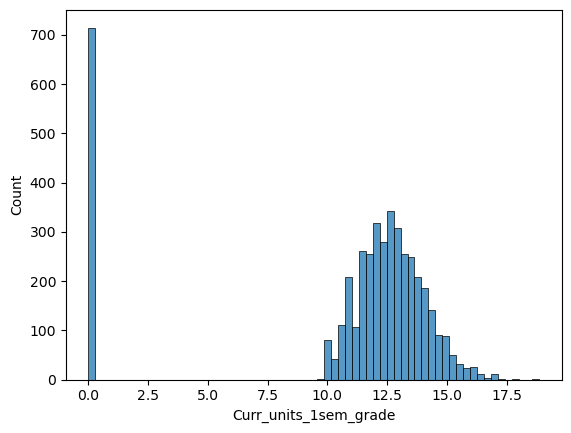

In [116]:
sns.histplot(data=df_clean, x="Curr_units_1sem_grade")

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

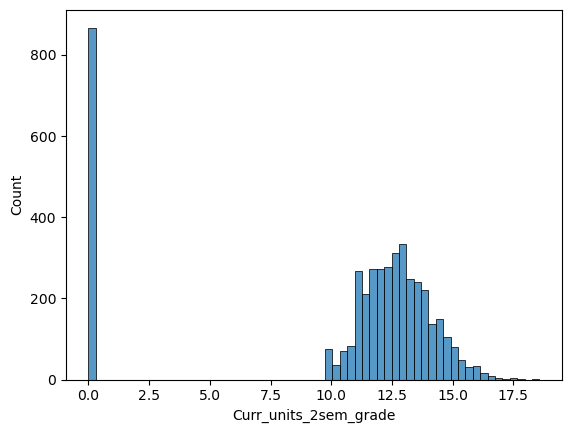

In [118]:
sns.histplot(data=df_clean, x="Curr_units_2sem_grade")

In [122]:
#Df select different rows to 0 in A/B and eliminat thems
df_clean = df_clean[(df_clean["Curr_units_1sem_grade"] > 0) & (df_clean["Curr_units_2sem_grade"] > 0)].copy()

print("dimension of df_clean", df_clean.shape)

dimension of df_clean (3496, 37)


In [124]:
df_clean.describe()

,Appl_mode,Appl_order,Course,Day/evening attend,Prev_qualif,Prev_qualif_grade,Mother's_qualif,Father's_qualif,Mother's_occup,Admi_grade,...,Curr_units_1sem_noeval,Curr_units_2sem_cred,Curr_units_2sem_enrol,Curr_units_2sem_eval,Curr_units_2sem_appvd,Curr_units_2sem_grade,Curr_units_2sem_noevaluat,Unemploy_rate,Infl_rate,GDP
count,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,...,3496.000000,3496.000000,3496.00000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000
mean,17.741133,1.764874,9220.362700,0.895881,4.569508,132.649685,19.447654,22.328089,10.812071,127.157580,...,0.110126,0.681922,6.66619,9.061785,5.567792,12.747317,0.117563,11.551201,1.206236,0.063435
std,17.401895,1.343317,1093.916375,0.305459,10.490122,13.053480,15.657497,15.319363,26.818179,13.882074,...,0.569768,2.134015,1.91429,3.163574,2.281099,1.370904,0.584169,2.641430,1.370071,2.266183
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,1.00000,1.000000,1.000000,10.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9119.000000,1.000000,1.000000,124.850000,2.000000,3.000000,4.000000,118.400000,...,0.000000,0.000000,6.00000,7.000000,4.000000,11.750000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9254.000000,1.000000,1.000000,133.000000,19.000000,19.000000,5.000000,126.300000,...,0.000000,0.000000,6.00000,8.000000,6.000000,12.666667,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.500000,...,0.000000,0.000000,8.00000,10.000000,6.000000,13.666667,0.000000,13.900000,2.600000,1.790000
max,53.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,12.000000,19.000000,23.00000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

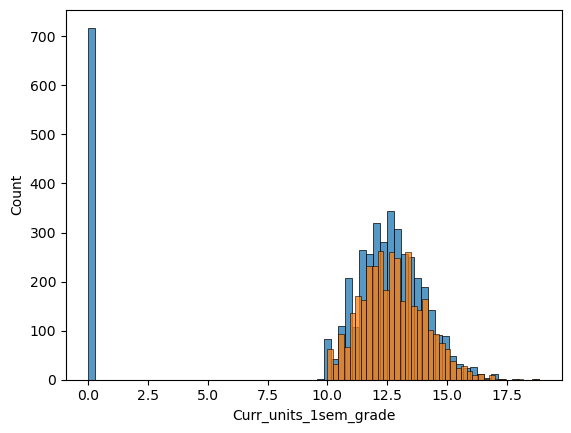

In [126]:
#Compare the histplot between df and df1 to see the effect of the previous code - 1sem

sns.histplot(data=df, x="Curr_units_1sem_grade")
sns.histplot(data=df_clean, x="Curr_units_1sem_grade")

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

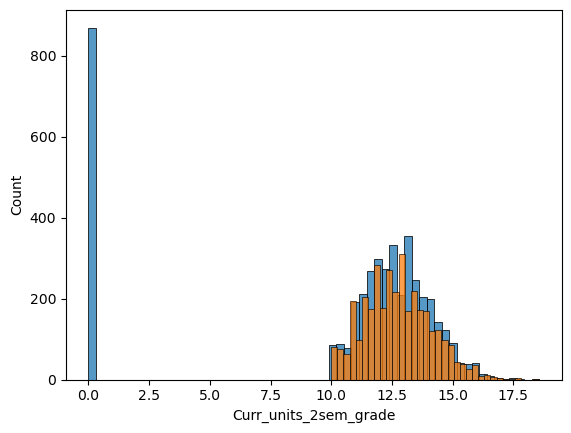

In [128]:
#Compare the histplot between df and df1 to see the effect of the previous code - 2sem

sns.histplot(data=df, x="Curr_units_2sem_grade")
sns.histplot(data=df_clean, x="Curr_units_2sem_grade")

In [72]:
# Indicate the unique values in the columns
df_clean = df.copy()

columns = ['Curr_units_1sem_cred', 'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
           'Curr_units_1sem_appvd', 'Curr_units_1sem_noeval', 'Curr_units_2sem_cred',
           'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
           'Curr_units_2sem_appvd', 'Curr_units_2sem_noevaluat']

# Conversion from nan to 0 and fill them with 0
for col in columns :
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

df_clean[columns] = df_clean[columns].fillna(0)

print("Updated data types for numeric columns:")
print(df_clean[columns].dtypes)

Updated data types for numeric columns:
Curr_units_1sem_cred         float64
Curr_units_1sem_enrol          int64
Curr_units_1sem_eval           int64
Curr_units_1sem_appvd          int64
Curr_units_1sem_noeval         int64
Curr_units_2sem_cred           int64
Curr_units_2sem_enrol        float64
Curr_units_2sem_eval           int64
Curr_units_2sem_appvd          int64
Curr_units_2sem_noevaluat      int64
dtype: object


In [130]:
#Rename columns
df_clean = df_clean.rename(columns={"Marital status": "Marital_status", "Application mode": "Appl_mode", "Application order": "Appl_order", "Daytime/evening attendance": "Day/evening attend", "Previous qualification": "Prev_qualif", "Previous qualification (grade)": "Prev_qualif_grade", "Nacionality": "Nationality", "Mother's qualification": "Mother's_qualif", "Father's qualification": "Father's_qualif", "Mother's occupation": "Mother's_occup", "Father's occupation": "Father's_occup", "Admission grade": "Admi_grade", "Educational special needs": "Educ_special_needs", "Tuition fees up to date": "Tuit_fees_upto_date", "Scholarship holder": "Scholar_holder", "Age at enrollment": "Age_enrollment", "International": "Intl", "Curricular units 1st sem (credited)": "Curr_units_1sem_cred", "Curricular units 1st sem (enrolled)": "Curr_units_1sem_enrol", "Curricular units 1st sem (evaluations)": "Curr_units_1sem_eval", "Curricular units 1st sem (approved)": "Curr_units_1sem_appvd", "Curricular units 1st sem (grade)": "Curr_units_1sem_grade", "Curricular units 1st sem (without evaluations)": "Curr_units_1sem_noeval","Curricular units 2nd sem (credited)": "Curr_units_2sem_cred", "Curricular units 2nd sem (enrolled)": "Curr_units_2sem_enrol", "Curricular units 2nd sem (evaluations)": "Curr_units_2sem_eval", "Curricular units 2nd sem (approved)": "Curr_units_2sem_appvd", "Curricular units 2nd sem (grade)": "Curr_units_2sem_grade", "Curricular units 2nd sem (without evaluations)": "Curr_units_2sem_noevaluat", "Unemployment rate": "Unemploy_rate", "Inflation rate": "Infl_rate"})
df_clean.columns

Index(['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
       'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
       'Mother's_qualif', 'Father's_qualif', 'Mother's_occup',
       'Father's_occup', 'Admi_grade', 'Displaced', 'Educ_special_needs',
       'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder',
       'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
       'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
       'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
       'Curr_units_1sem_noeval', 'Curr_units_2sem_cred',
       'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
       'Curr_units_2sem_appvd', 'Curr_units_2sem_grade',
       'Curr_units_2sem_noevaluat', 'Unemploy_rate', 'Infl_rate', 'GDP',
       'Target'],
      dtype='str')

In [132]:
df_clean["Curr_units_1sem_cred"].unique()

<StringArray>
[ '0',  '2',  '3',  '6',  '7', '13',  '4',  '1',  '5', '19', '11',  '8', '10',
  '9', '15', '12', '14', '18', '17', '16', '20', 'Na']
Length: 22, dtype: str

In [134]:
# Indicate the unique values in the columns
columns = ['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
           'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
            "Mother's_qualif", "Father's_qualif", "Mother's_occup",
            "Father's_occup", 'Admi_grade', 'Displaced', 'Educ_special_needs',
            'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder', 'Unemploy_rate', 'Infl_rate', 'GDP',
            'Target']

for i in columns:
    print(f'{i} unique values:' , df_clean[i].unique())

Marital_status unique values: <StringArray>
['1', '2', '4', '?', '3', '5', '6']
Length: 7, dtype: str
Appl_mode unique values: [15. 17. 39.  1. 53. 18. 44. 51. 43. 42.  7. 16.  5.  2. 10. 26. 27.]
Appl_order unique values: [1. 2. 3. 4. 6. 5. 9. 0.]
Course unique values: [9254. 9773. 8014. 9991. 9500. 9238. 9670. 9085. 9130. 9853. 9556. 9147.
 9003. 9070. 9119.  171.   33.]
Day/evening attend unique values: [1 0]
Prev_qualif unique values: [ 1 19 42 39 40  4 12  3 43 15  6 38  2  9 10 14]
Prev_qualif_grade unique values: [160.  122.  100.  133.1 142.  137.  138.  139.  136.  110.  149.  135.
 140.  127.  125.  126.  151.  115.  150.  143.  130.  120.  133.  103.
 154.  132.  167.  129.  141.  118.  106.  121.  114.  124.  113.  111.
 123.  131.  158.  117.  153.  178.  116.  134.  128.  148.  155.  145.
 146.  152.  170.  112.  119.  107.  156.   96.  161.  166.  147.  144.
 102.  101.  172.  105.  180.  165.  190.  162.  164.  108.  159.  117.4
 175.  163.  133.8 176.  168.   97.  157.

In [136]:
#0 pass to be number of the categorical that does not have any answer
df_clean = df.replace("?", 0)

In [210]:
# Clean target just in case some missing values
df_clean['Target'] = df_clean['Target'].astype(str).str.strip()

# Usar replace en lugar de map
target_mapping = {'Graduate': 0, 'Grad': 0, 'graduate': 0, 'Dropout': 1, 'Drop': 1, 'dropout': 1, 'Enrolled': 2, 'enrolled': 2}

df_clean['Target'] = df_clean['Target'].replace
df_clean = df_clean.dropna().reset_index(drop=True)

In [140]:
df_clean["Nationality"].unique()
df_clean["Tuit_fees_upto_date"].unique()
df_clean["Marital_status"].unique()

array(['1', '62', '6', '41', '26', '103', '13', '25', '21', '101', '11',
       '22', '32', '100', '24', '109', '2', '108', '105', '14', 0, '17'],
      dtype=object)

array(['1', '0', nan, 0], dtype=object)

array(['1', '2', '4', 0, '3', '5', '6'], dtype=object)

In [142]:
df_clean = df.replace("Five", 5)

In [144]:
df_clean["Father's_occup"].unique()

array(['9', '3', '7', '10', '5', '8', '4', '1', '2', '124', '6', '0',
       '90', '175', '121', '99', '144', '195', '192', '161', '193', '151',
       '182', '132', '131', '194', '163', '135', '143', '171', '103',
       '172', '152', '183', '122', '102', '181', '134', '123', '112',
       '153', '174', '141', '114', nan, 5, '101', '154'], dtype=object)

(array([  6.,  90.,  40., 153., 211., 536., 439., 622., 935., 596., 238.,
        255.,  69., 135.,  29.,  39.,   8.,  14.,   2.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

Text(0, 0.5, 'Frecuencia')

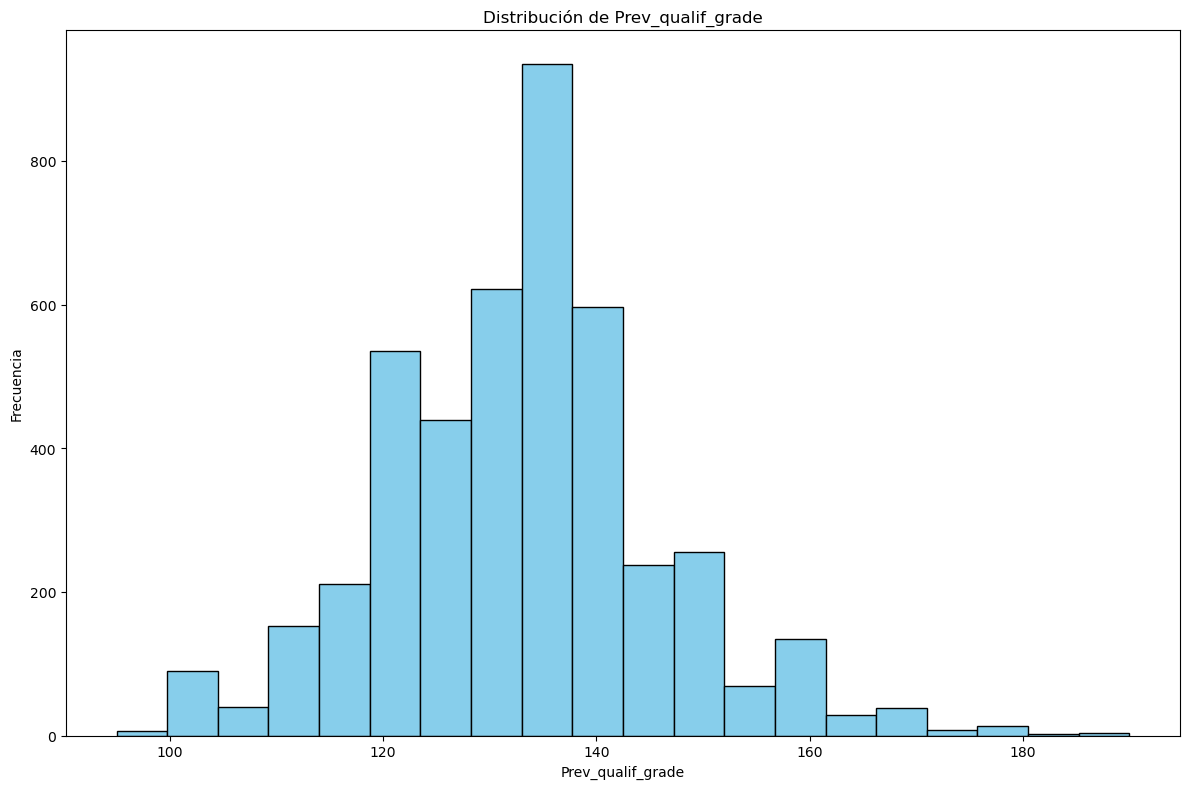

(array([ 50., 190., 153., 336., 474., 699., 623., 621., 352., 353., 140.,
        181.,  94.,  78.,  32.,  24.,   6.,  10.,   3.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Admi_grade')

Text(0.5, 0, 'Admi_grade')

Text(0, 0.5, 'Frecuencia')

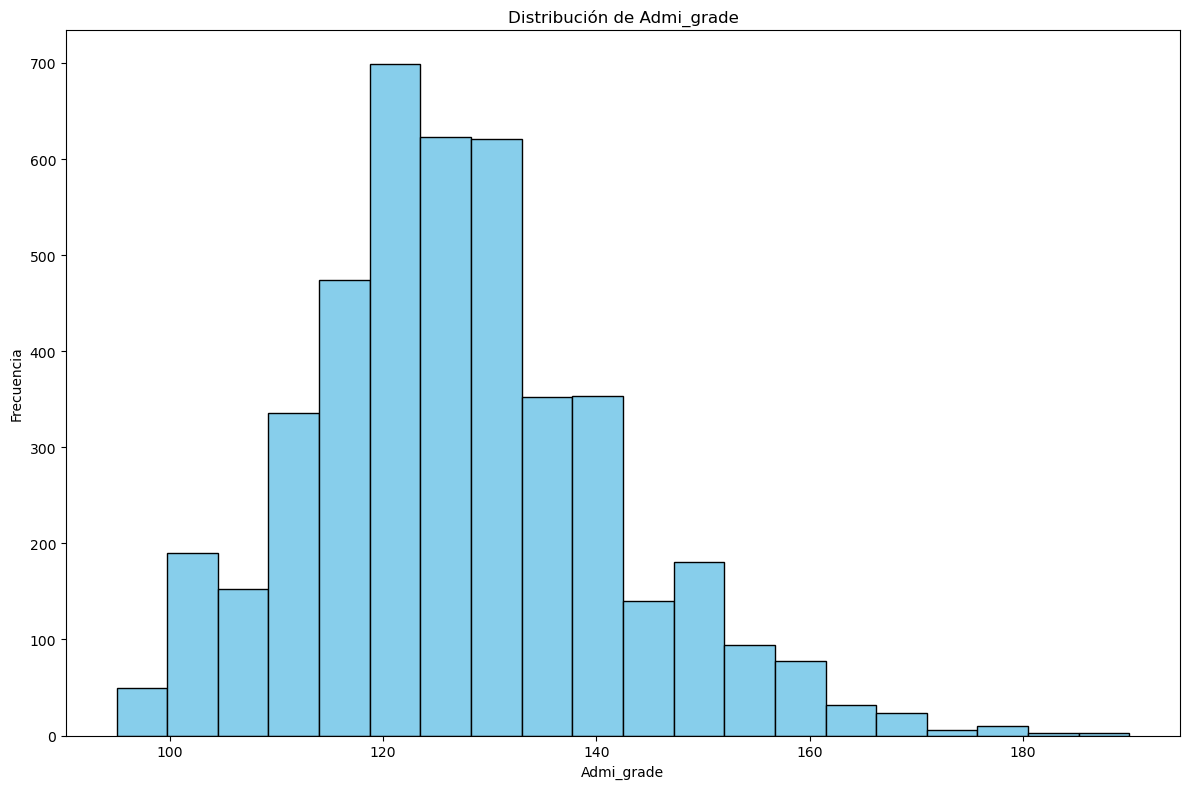

(array([571.,   0.,   0., 368., 533.,   0.,   0., 525., 414.,   0.,   0.,
        864.,   0.,   0., 390.,   0.,   0.,   0., 397., 362.]),
 array([ 7.6 ,  8.03,  8.46,  8.89,  9.32,  9.75, 10.18, 10.61, 11.04,
        11.47, 11.9 , 12.33, 12.76, 13.19, 13.62, 14.05, 14.48, 14.91,
        15.34, 15.77, 16.2 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Unemploy_rate')

Text(0.5, 0, 'Unemploy_rate')

Text(0, 0.5, 'Frecuencia')

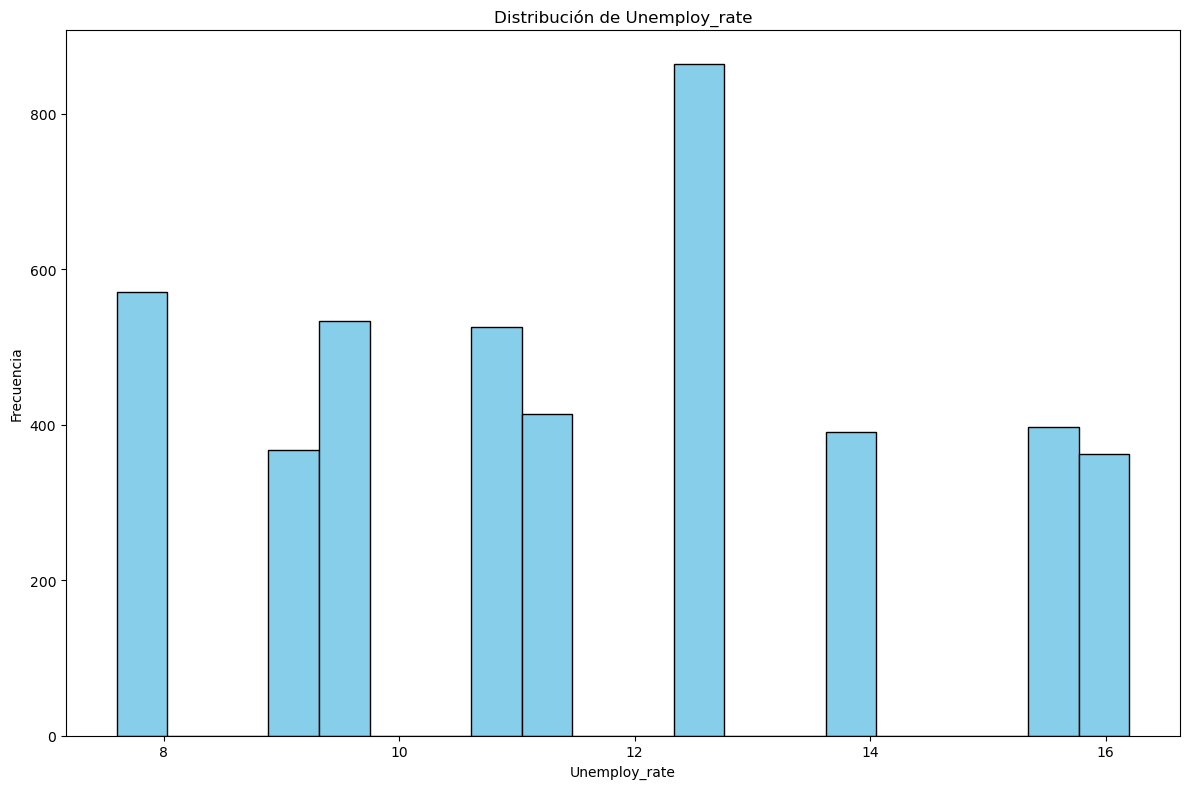

(array([533.,   0., 390.,   0., 362., 445., 414.,   0.,   0., 893.,   0.,
          0.,   0.,   0.,   0., 571., 397.,   0.,   0., 419.]),
 array([-0.8  , -0.575, -0.35 , -0.125,  0.1  ,  0.325,  0.55 ,  0.775,
         1.   ,  1.225,  1.45 ,  1.675,  1.9  ,  2.125,  2.35 ,  2.575,
         2.8  ,  3.025,  3.25 ,  3.475,  3.7  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Infl_rate')

Text(0.5, 0, 'Infl_rate')

Text(0, 0.5, 'Frecuencia')

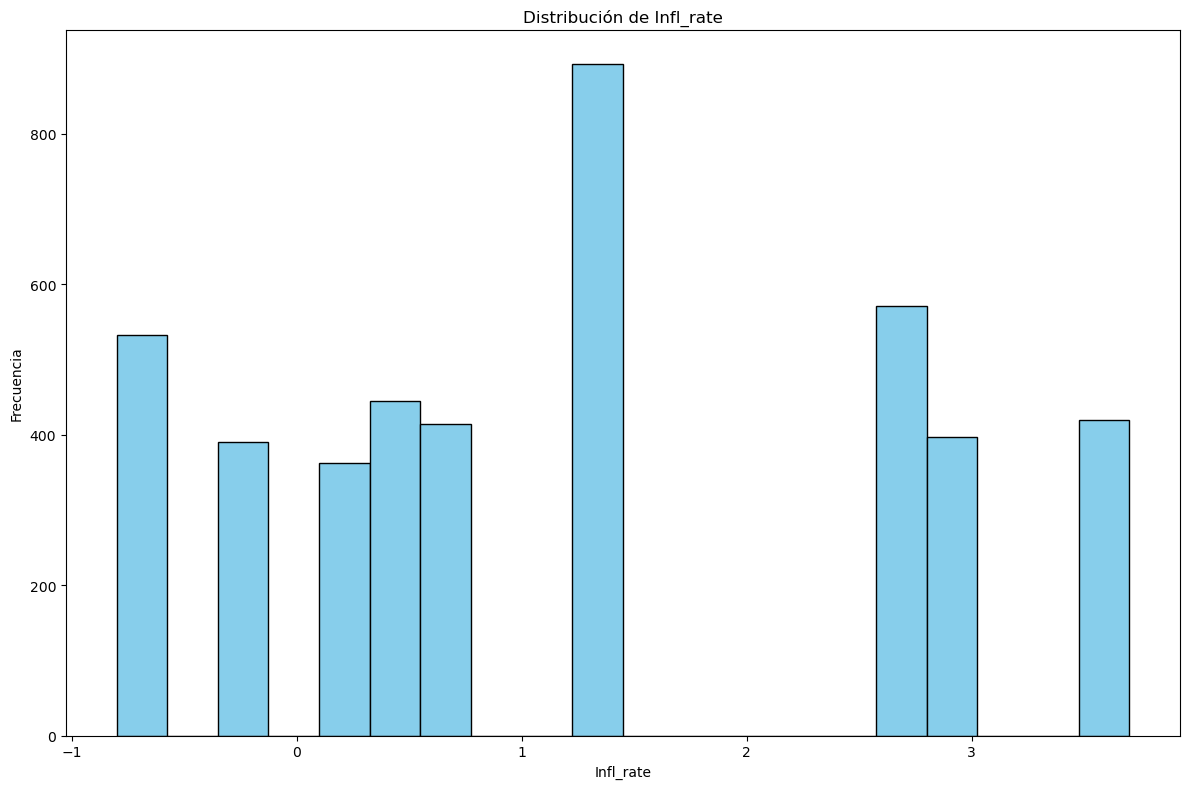

(array([397.,   0., 533.,   0.,   0.,   0., 419.,   0., 362.,   0.,   0.,
        571., 390.,   0.,   0., 970., 414.,   0.,   0., 368.]),
 array([-4.06  , -3.6815, -3.303 , -2.9245, -2.546 , -2.1675, -1.789 ,
        -1.4105, -1.032 , -0.6535, -0.275 ,  0.1035,  0.482 ,  0.8605,
         1.239 ,  1.6175,  1.996 ,  2.3745,  2.753 ,  3.1315,  3.51  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de GDP')

Text(0.5, 0, 'GDP')

Text(0, 0.5, 'Frecuencia')

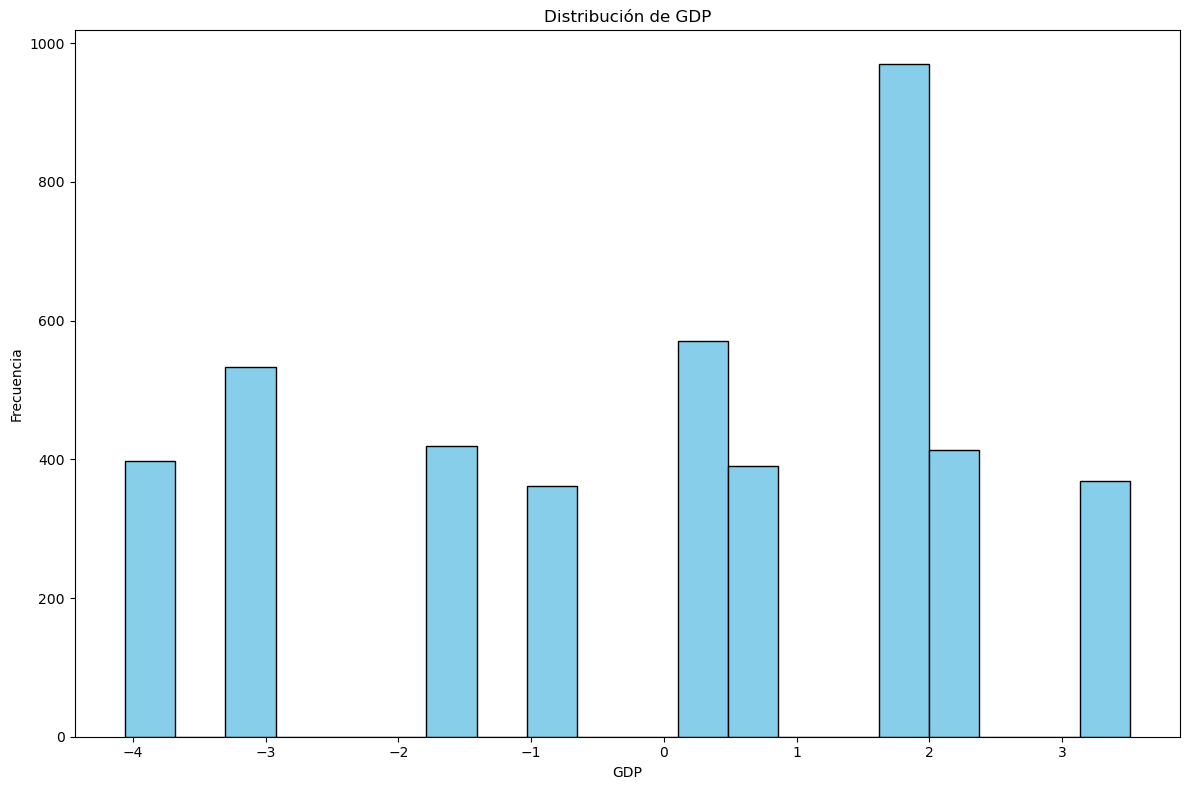

In [146]:
#Continuous columns
cont_col = ['Prev_qualif_grade', 'Admi_grade', 'Unemploy_rate', 'Infl_rate', 'GDP']

df_clean[cont_col] = df_clean[cont_col].apply(pd.to_numeric, errors="coerce")

for i in cont_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Graficar histograma
    ax.hist(df[i].dropna(), bins=20, color='skyblue', edgecolor='black')
    
    ax.set_title(f'Distribución de {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frecuencia')
    
    plt.tight_layout()
    plt.show()

(array([3.918e+03, 0.000e+00, 0.000e+00, 3.790e+02, 0.000e+00, 0.000e+00,
        9.100e+01, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 4.000e+00, 0.000e+00, 0.000e+00, 2.500e+01, 0.000e+00,
        0.000e+00, 6.000e+00]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. , 3.3, 3.6,
        3.9, 4.2, 4.5, 4.8, 5.1, 5.4, 5.7, 6. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Marital_status')

Text(0.5, 0, 'Marital_status')

Text(0, 0.5, 'Frecuencia')

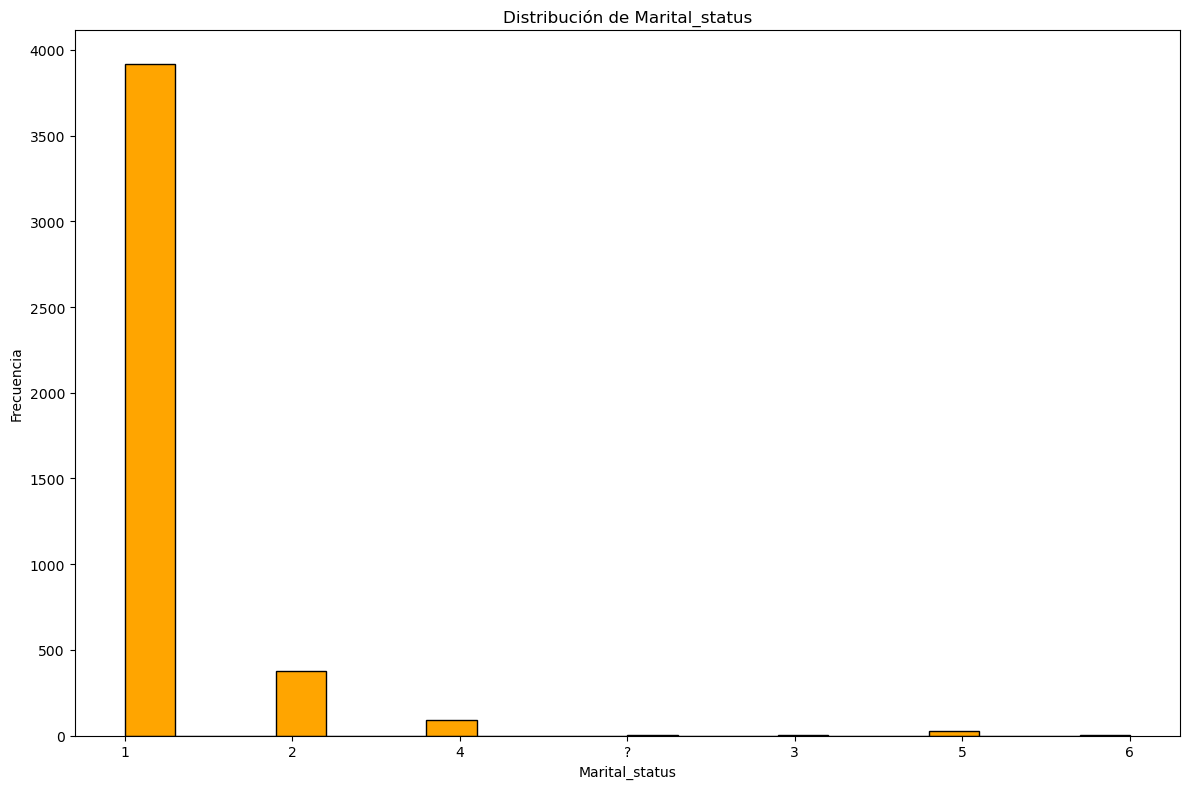

(array([1.711e+03, 1.600e+01, 1.390e+02, 1.000e+01, 0.000e+00, 9.400e+02,
        1.240e+02, 0.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 7.850e+02, 7.700e+01, 5.240e+02, 0.000e+00, 5.900e+01,
        3.500e+01, 1.000e+00]),
 array([ 1. ,  3.8,  6.6,  9.4, 12.2, 15. , 17.8, 20.6, 23.4, 26.2, 29. ,
        31.8, 34.6, 37.4, 40.2, 43. , 45.8, 48.6, 51.4, 54.2, 57. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Appl_mode')

Text(0.5, 0, 'Appl_mode')

Text(0, 0.5, 'Frecuencia')

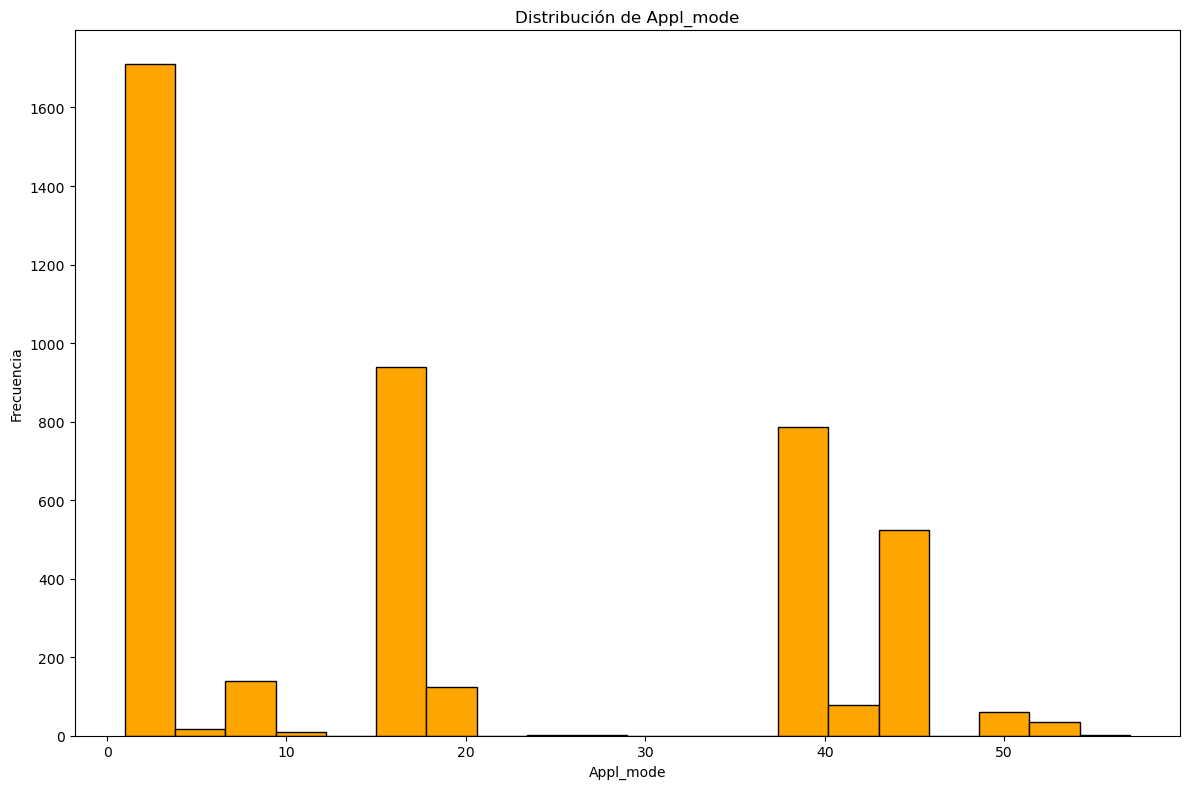

(array([1.000e+00, 0.000e+00, 3.026e+03, 0.000e+00, 5.470e+02, 0.000e+00,
        3.080e+02, 0.000e+00, 2.490e+02, 0.000e+00, 0.000e+00, 1.540e+02,
        0.000e+00, 1.370e+02, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Appl_order')

Text(0.5, 0, 'Appl_order')

Text(0, 0.5, 'Frecuencia')

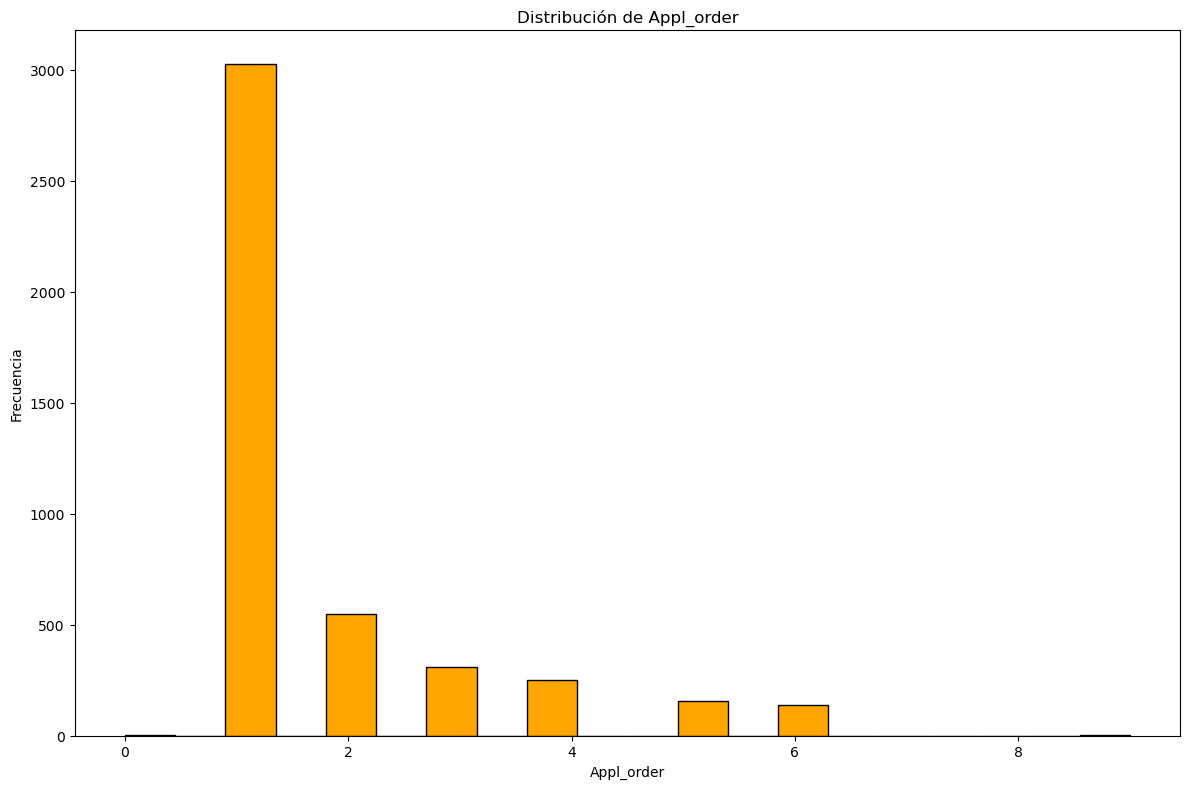

(array([ 227.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,  215.,    0.,
        2069., 1910.]),
 array([  33. ,  530.9, 1028.8, 1526.7, 2024.6, 2522.5, 3020.4, 3518.3,
        4016.2, 4514.1, 5012. , 5509.9, 6007.8, 6505.7, 7003.6, 7501.5,
        7999.4, 8497.3, 8995.2, 9493.1, 9991. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Course')

Text(0.5, 0, 'Course')

Text(0, 0.5, 'Frecuencia')

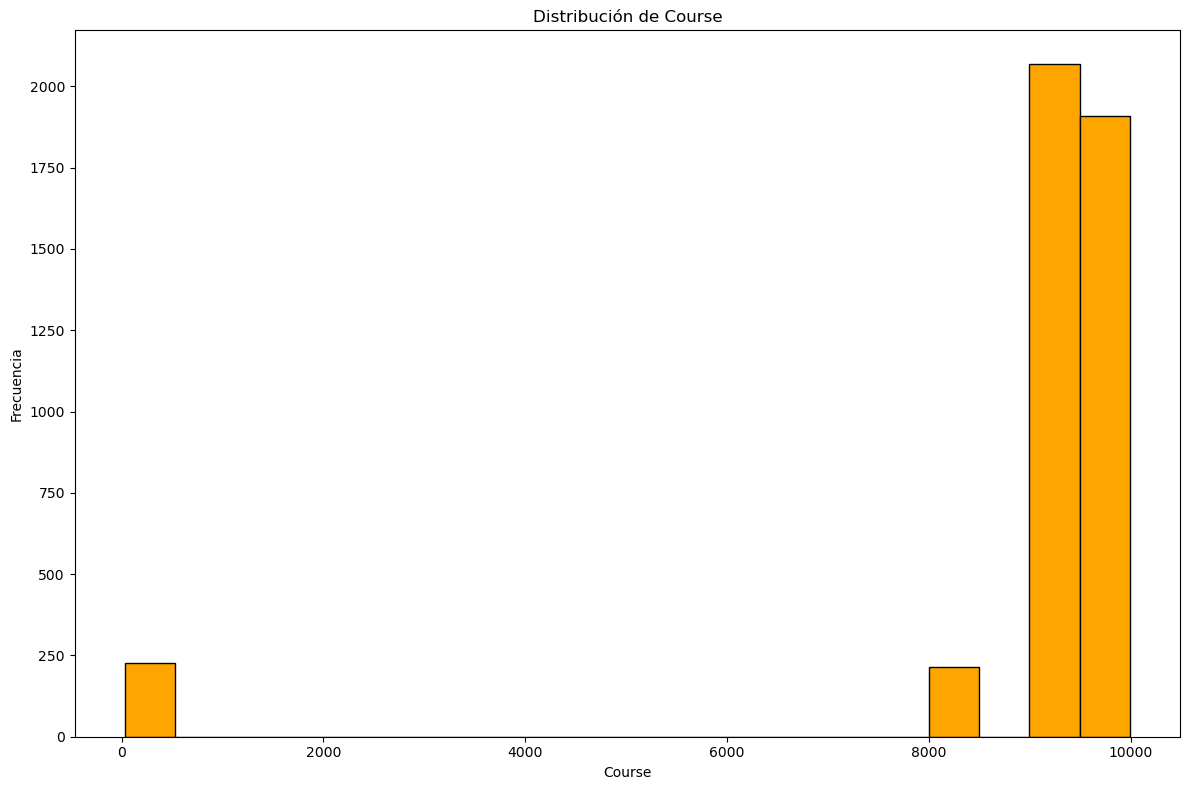

(array([ 483.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 3941.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Day/evening attend')

Text(0.5, 0, 'Day/evening attend')

Text(0, 0.5, 'Frecuencia')

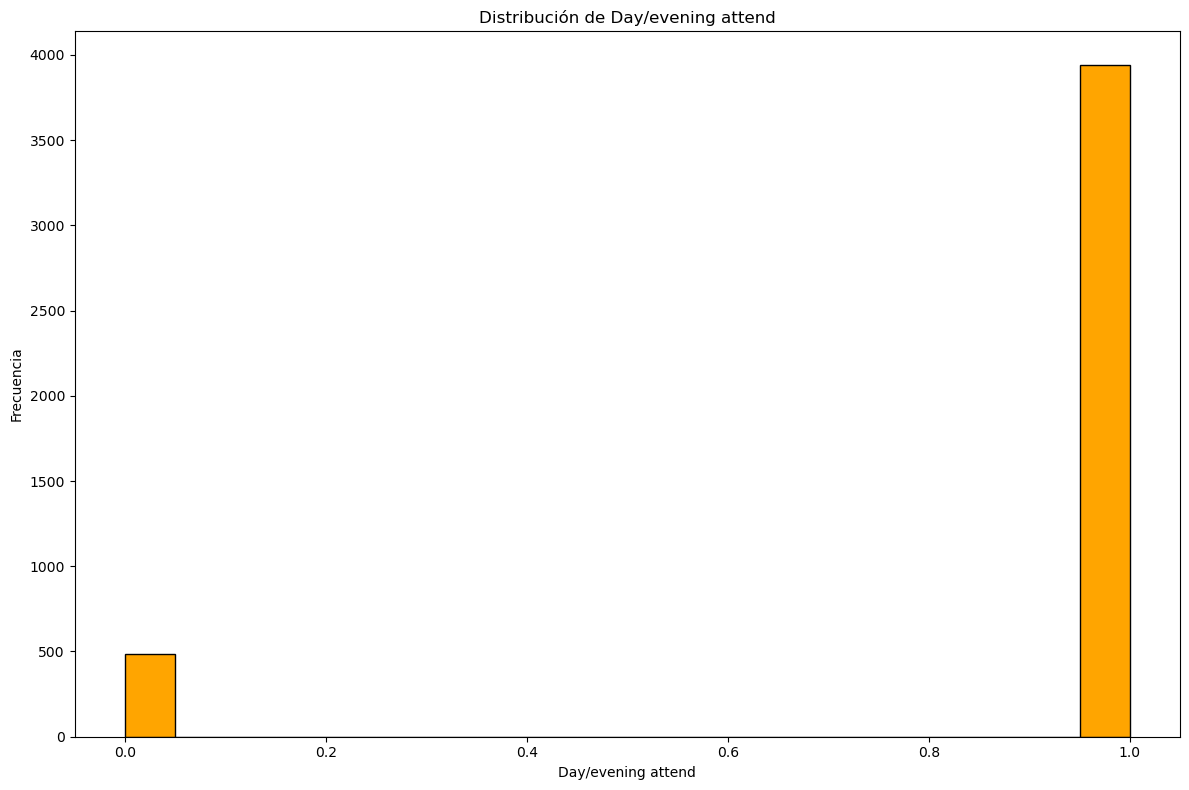

(array([  6.,  90.,  40., 153., 211., 536., 439., 622., 935., 596., 238.,
        255.,  69., 135.,  29.,  39.,   8.,  14.,   2.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

Text(0, 0.5, 'Frecuencia')

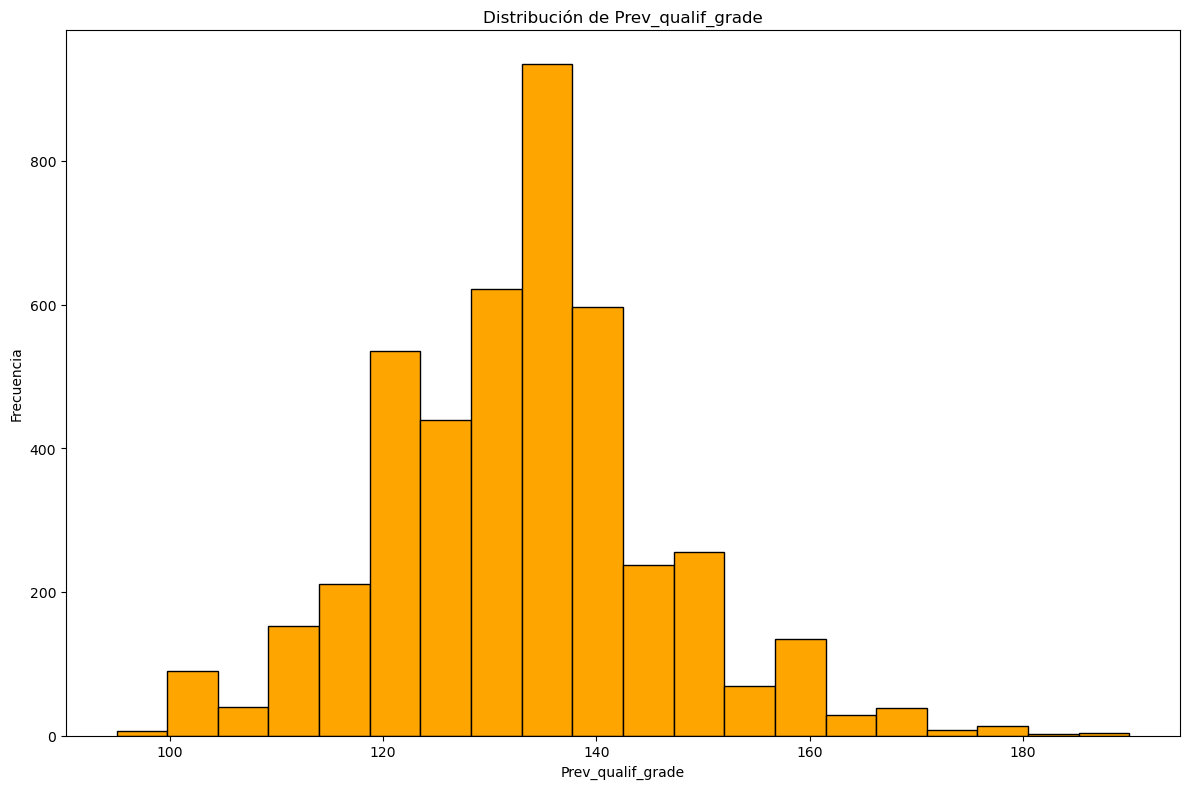

(array([4.315e+03, 1.300e+01, 3.800e+01, 1.400e+01, 3.000e+00, 1.000e+00,
        2.000e+00, 2.000e+00, 2.000e+00, 3.000e+00, 1.300e+01, 1.000e+00,
        3.000e+00, 5.000e+00, 1.000e+00, 2.000e+00, 1.000e+00, 2.000e+00,
        1.000e+00, 2.000e+00]),
 array([ 0.  ,  1.05,  2.1 ,  3.15,  4.2 ,  5.25,  6.3 ,  7.35,  8.4 ,
         9.45, 10.5 , 11.55, 12.6 , 13.65, 14.7 , 15.75, 16.8 , 17.85,
        18.9 , 19.95, 21.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Nationality')

Text(0.5, 0, 'Nationality')

Text(0, 0.5, 'Frecuencia')

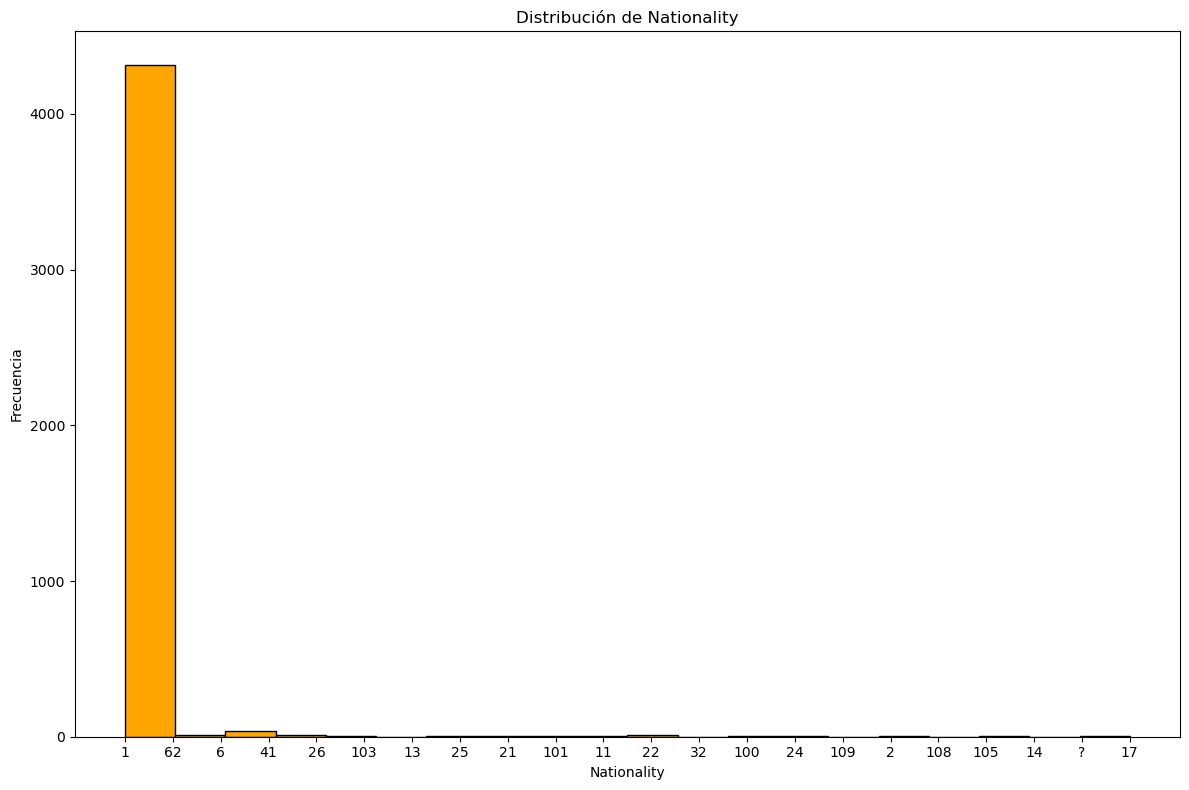

(array([1.590e+03, 7.000e+01, 4.000e+00, 8.000e+00, 6.000e+00, 4.200e+01,
        2.000e+00, 1.000e+00, 9.530e+02, 1.000e+00, 0.000e+00, 1.000e+00,
        1.000e+00, 6.000e+00, 0.000e+00, 1.330e+02, 1.012e+03, 5.700e+02,
        1.500e+01, 9.000e+00]),
 array([ 1.  ,  3.15,  5.3 ,  7.45,  9.6 , 11.75, 13.9 , 16.05, 18.2 ,
        20.35, 22.5 , 24.65, 26.8 , 28.95, 31.1 , 33.25, 35.4 , 37.55,
        39.7 , 41.85, 44.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Mother's_qualif")

Text(0.5, 0, "Mother's_qualif")

Text(0, 0.5, 'Frecuencia')

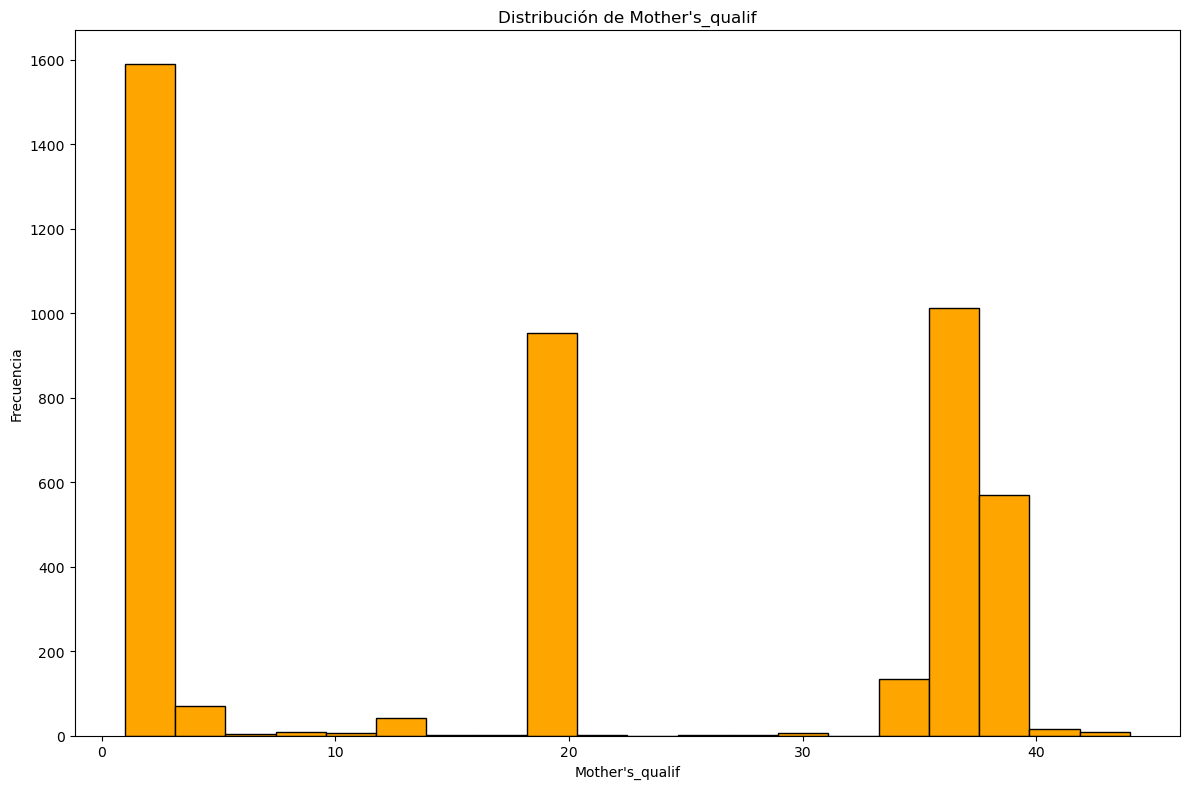

(array([1.254e+03, 5.700e+01, 2.000e+00, 5.000e+00, 1.200e+01, 3.900e+01,
        4.000e+00, 1.000e+00, 9.690e+02, 4.000e+00, 0.000e+00, 3.000e+00,
        1.000e+00, 8.000e+00, 1.000e+00, 1.140e+02, 1.216e+03, 7.220e+02,
        7.000e+00, 4.000e+00]),
 array([ 1.  ,  3.15,  5.3 ,  7.45,  9.6 , 11.75, 13.9 , 16.05, 18.2 ,
        20.35, 22.5 , 24.65, 26.8 , 28.95, 31.1 , 33.25, 35.4 , 37.55,
        39.7 , 41.85, 44.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Father's_qualif")

Text(0.5, 0, "Father's_qualif")

Text(0, 0.5, 'Frecuencia')

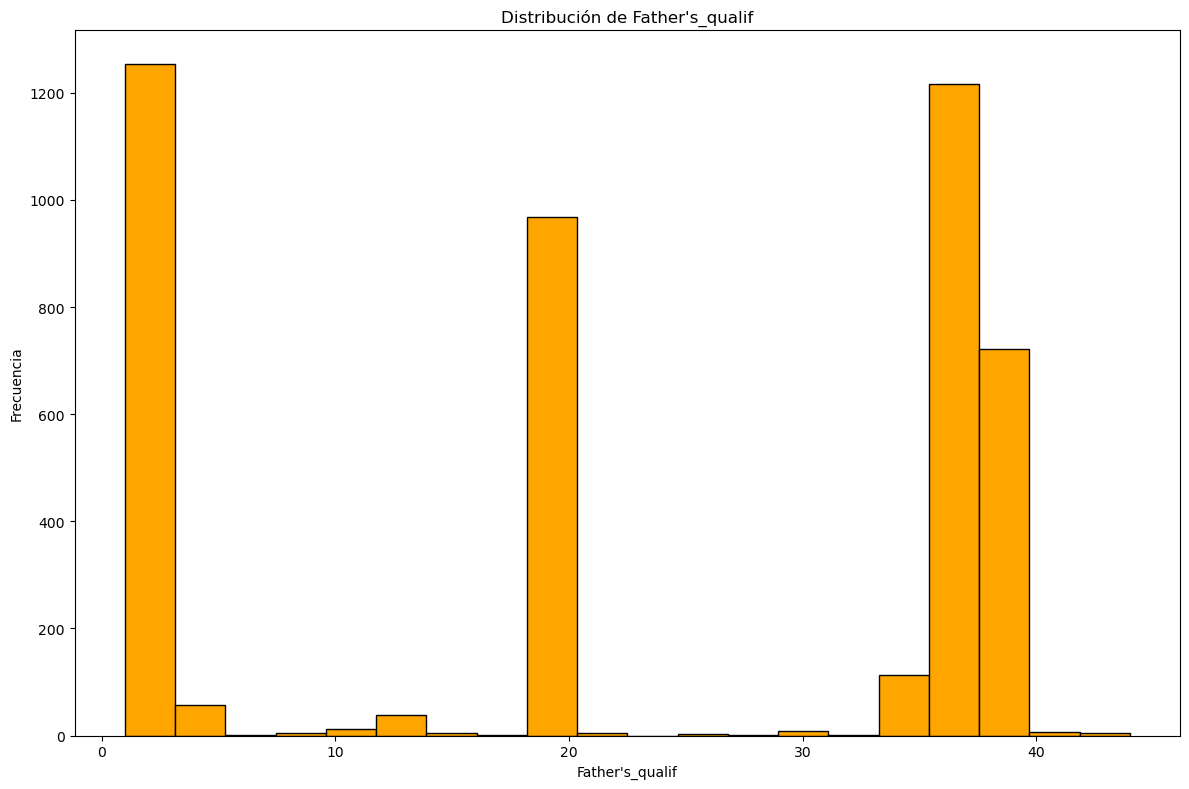

(array([4.237e+03, 4.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 7.000e+01, 1.700e+01, 0.000e+00,
        1.000e+01, 8.000e+00, 1.700e+01, 7.000e+00, 0.000e+00, 2.000e+00,
        5.000e+00, 4.600e+01]),
 array([  0. ,   9.7,  19.4,  29.1,  38.8,  48.5,  58.2,  67.9,  77.6,
         87.3,  97. , 106.7, 116.4, 126.1, 135.8, 145.5, 155.2, 164.9,
        174.6, 184.3, 194. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Mother's_occup")

Text(0.5, 0, "Mother's_occup")

Text(0, 0.5, 'Frecuencia')

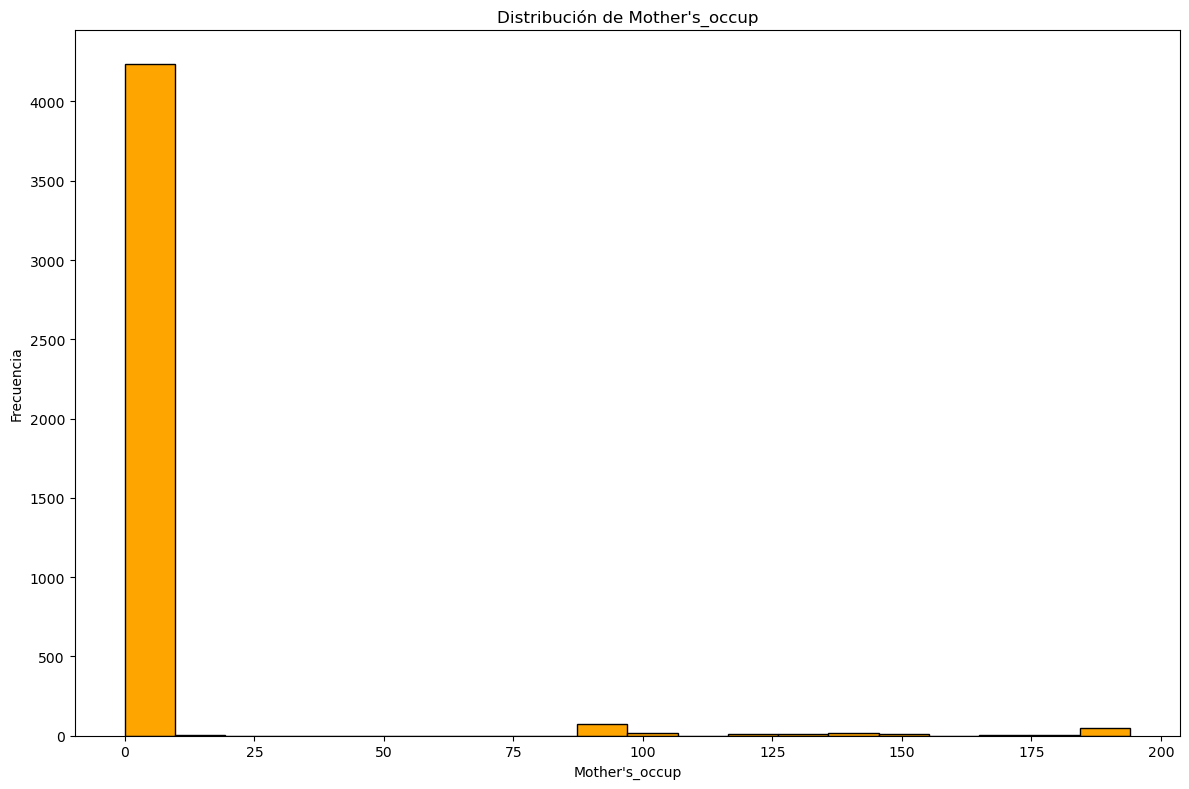

(array([2.06e+03, 7.81e+02, 7.03e+02, 3.32e+02, 3.70e+02, 6.90e+01,
        2.80e+01, 7.00e+00, 1.60e+01, 4.00e+00, 4.00e+00, 8.00e+00,
        9.00e+00, 9.00e+00, 5.00e+00, 5.00e+00, 6.00e+00, 2.00e+00,
        2.00e+00, 3.00e+00]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ,
        25.3, 27.6, 29.9, 32.2, 34.5, 36.8, 39.1, 41.4, 43.7, 46. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Father's_occup")

Text(0.5, 0, "Father's_occup")

Text(0, 0.5, 'Frecuencia')

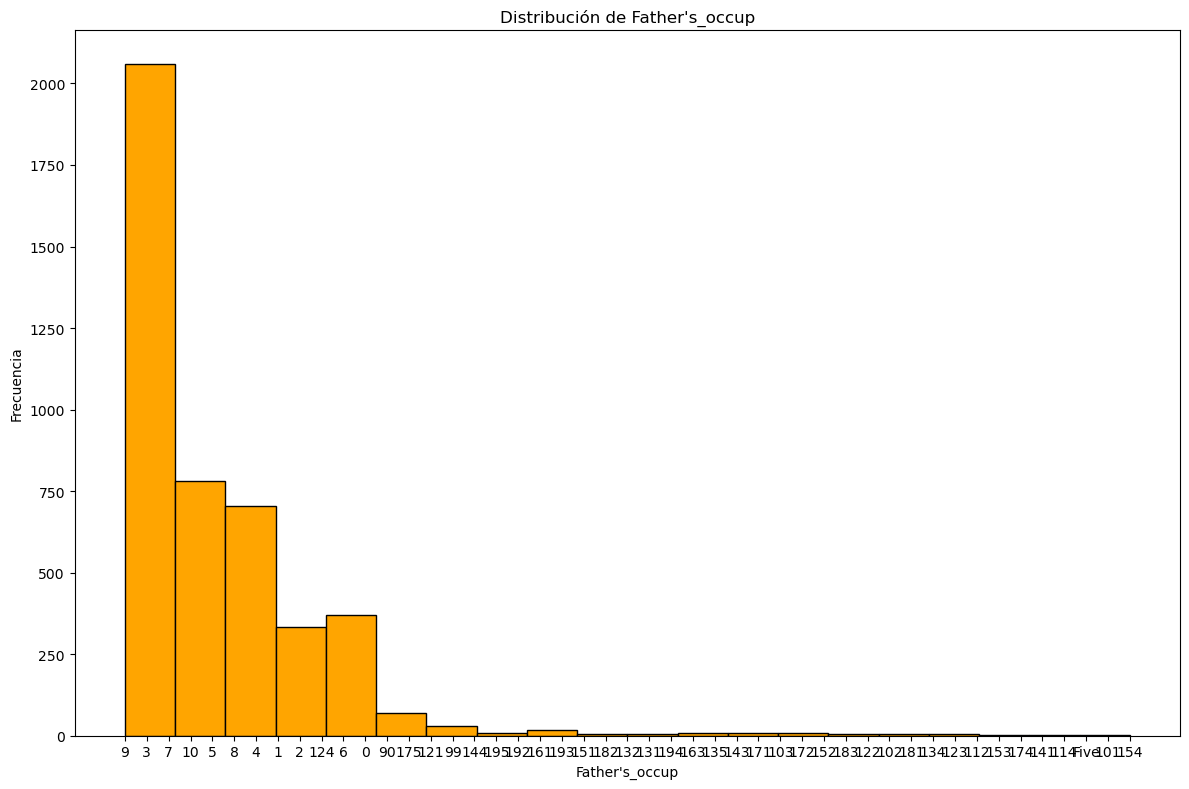

(array([2.425e+03, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.998e+03, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Displaced')

Text(0.5, 0, 'Displaced')

Text(0, 0.5, 'Frecuencia')

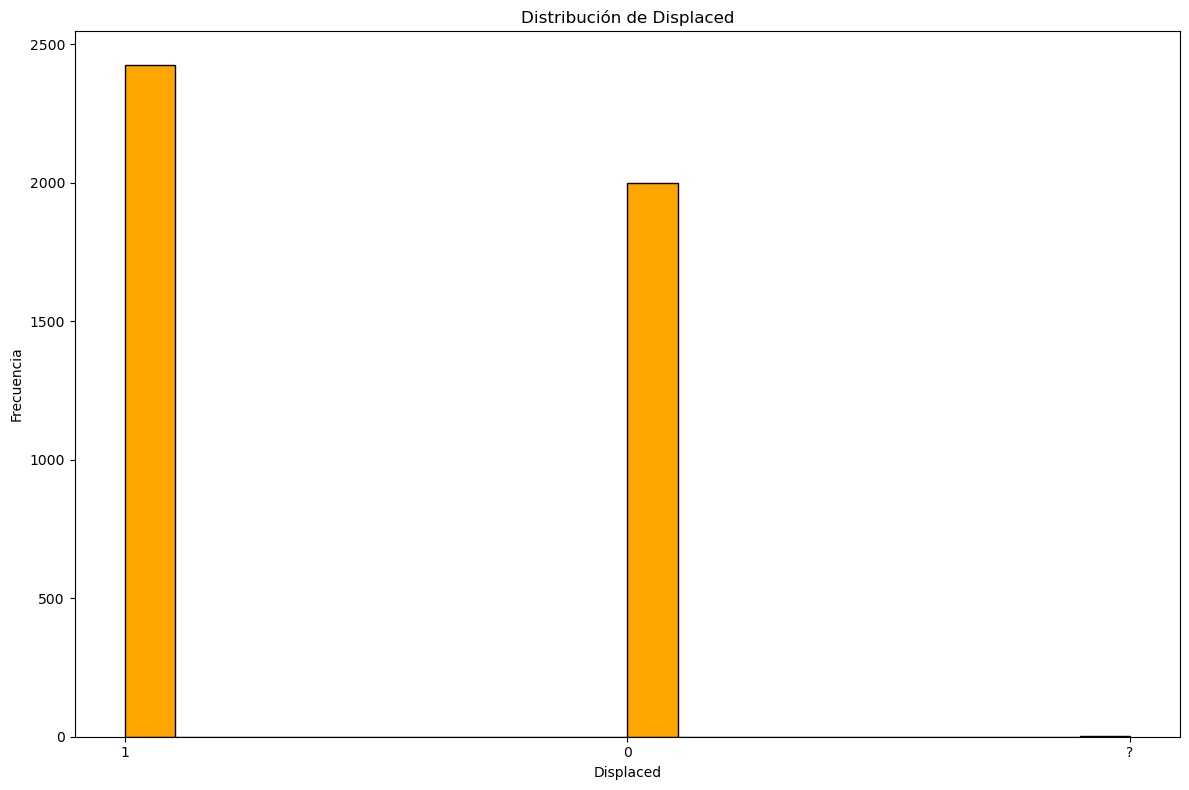

(array([4373.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,   51.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Educ_special_needs')

Text(0.5, 0, 'Educ_special_needs')

Text(0, 0.5, 'Frecuencia')

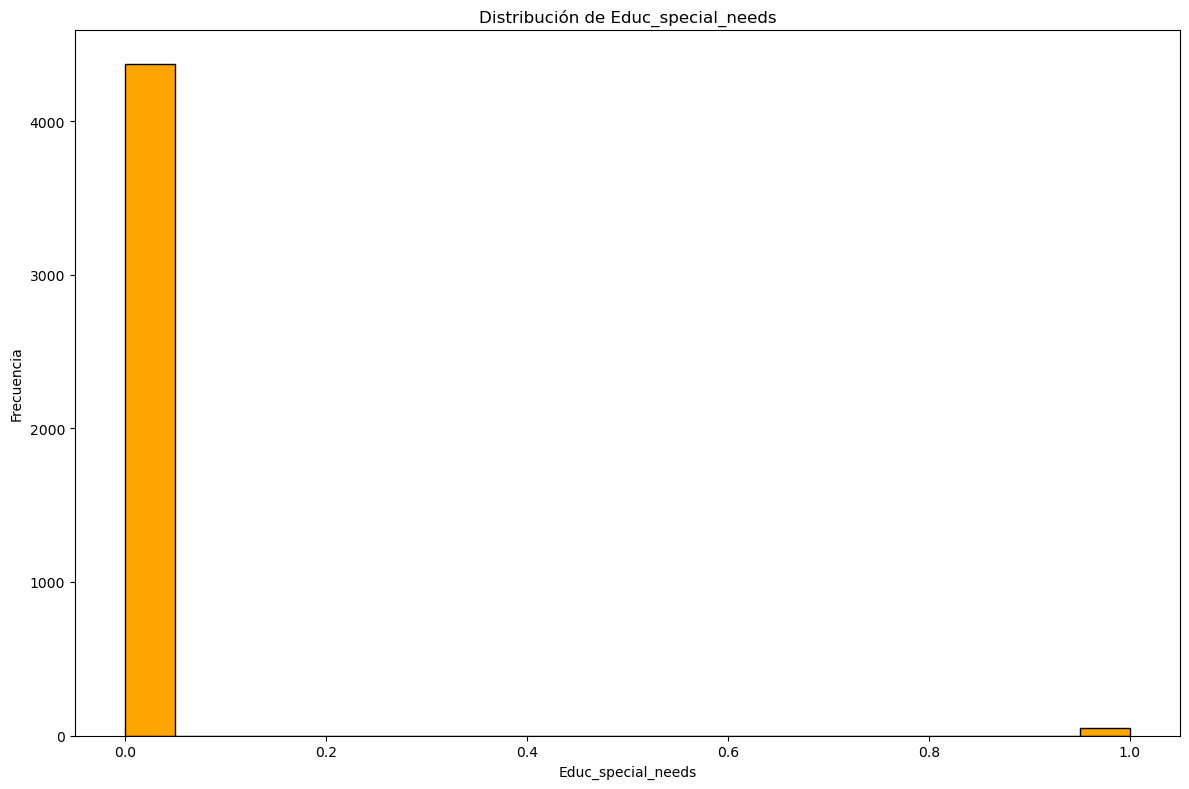

(array([3920.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,  503.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Debtor')

Text(0.5, 0, 'Debtor')

Text(0, 0.5, 'Frecuencia')

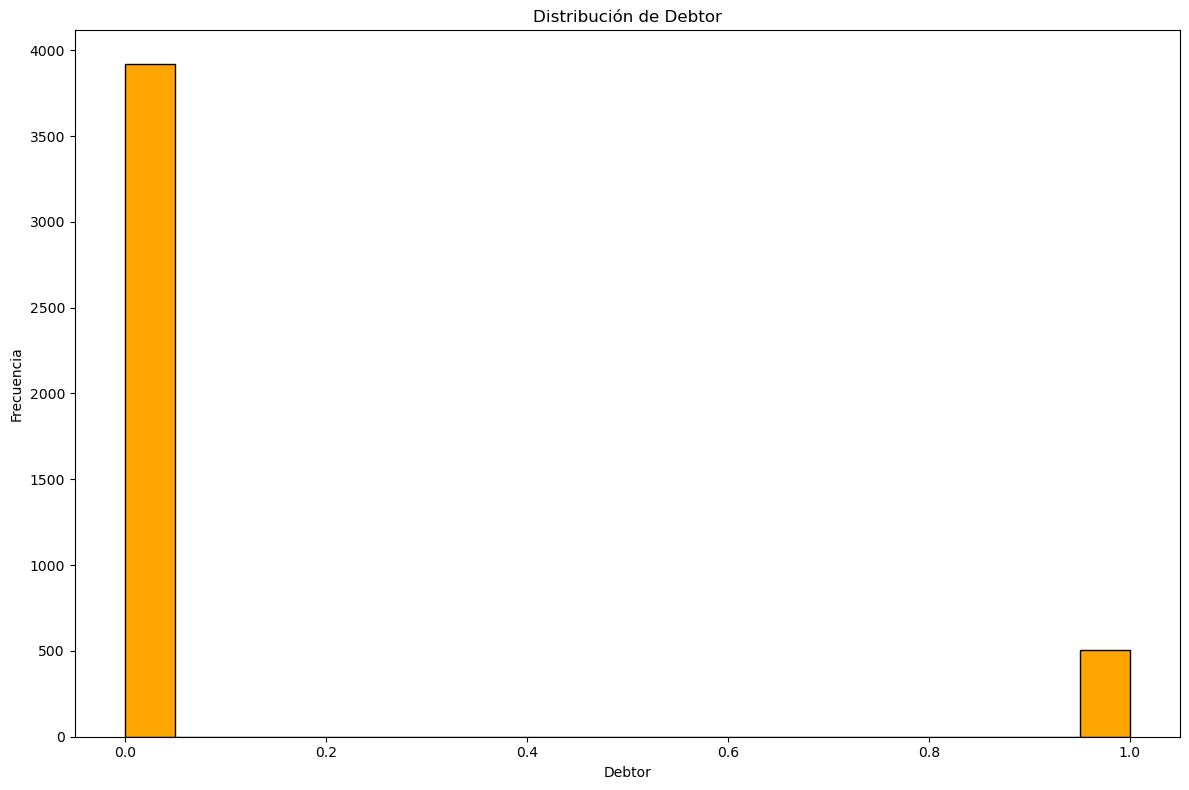

(array([3.895e+03, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 5.270e+02, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Tuit_fees_upto_date')

Text(0.5, 0, 'Tuit_fees_upto_date')

Text(0, 0.5, 'Frecuencia')

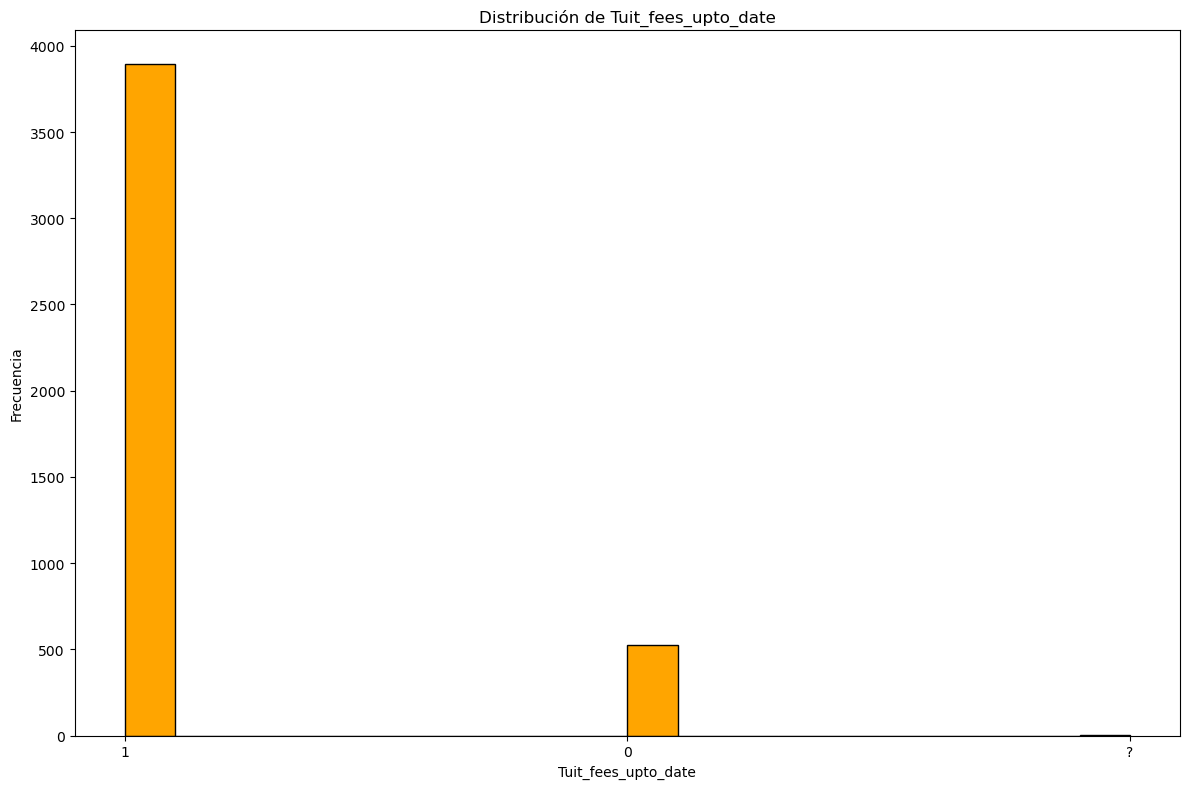

(array([2868.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 1556.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Gender')

Text(0.5, 0, 'Gender')

Text(0, 0.5, 'Frecuencia')

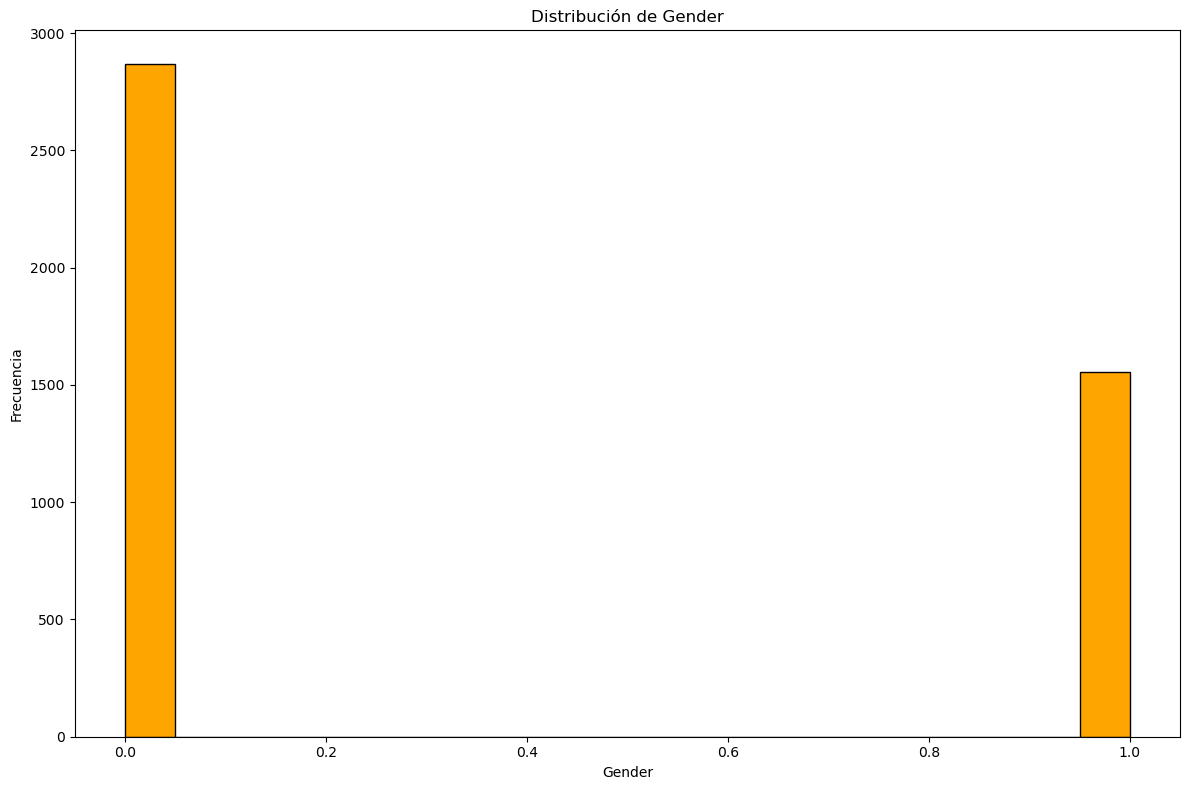

(array([3325.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 1099.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Scholar_holder')

Text(0.5, 0, 'Scholar_holder')

Text(0, 0.5, 'Frecuencia')

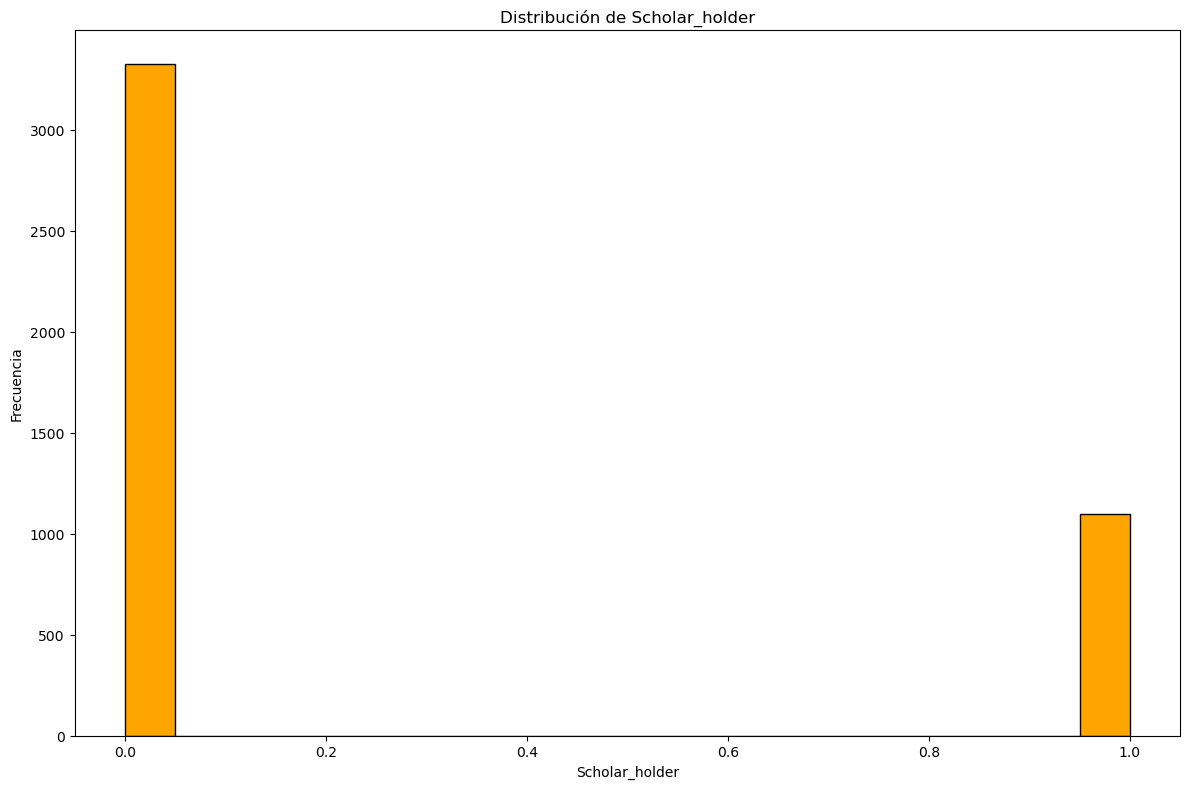

(array([1532., 1051.,  495.,  127.,   43.,  197.,  293.,   94.,  114.,
          53.,  113.,  104.,   84.,   37.,   43.,    3.,   18.,    8.,
           6.,    8.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ,
        25.3, 27.6, 29.9, 32.2, 34.5, 36.8, 39.1, 41.4, 43.7, 46. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Age_enrollment')

Text(0.5, 0, 'Age_enrollment')

Text(0, 0.5, 'Frecuencia')

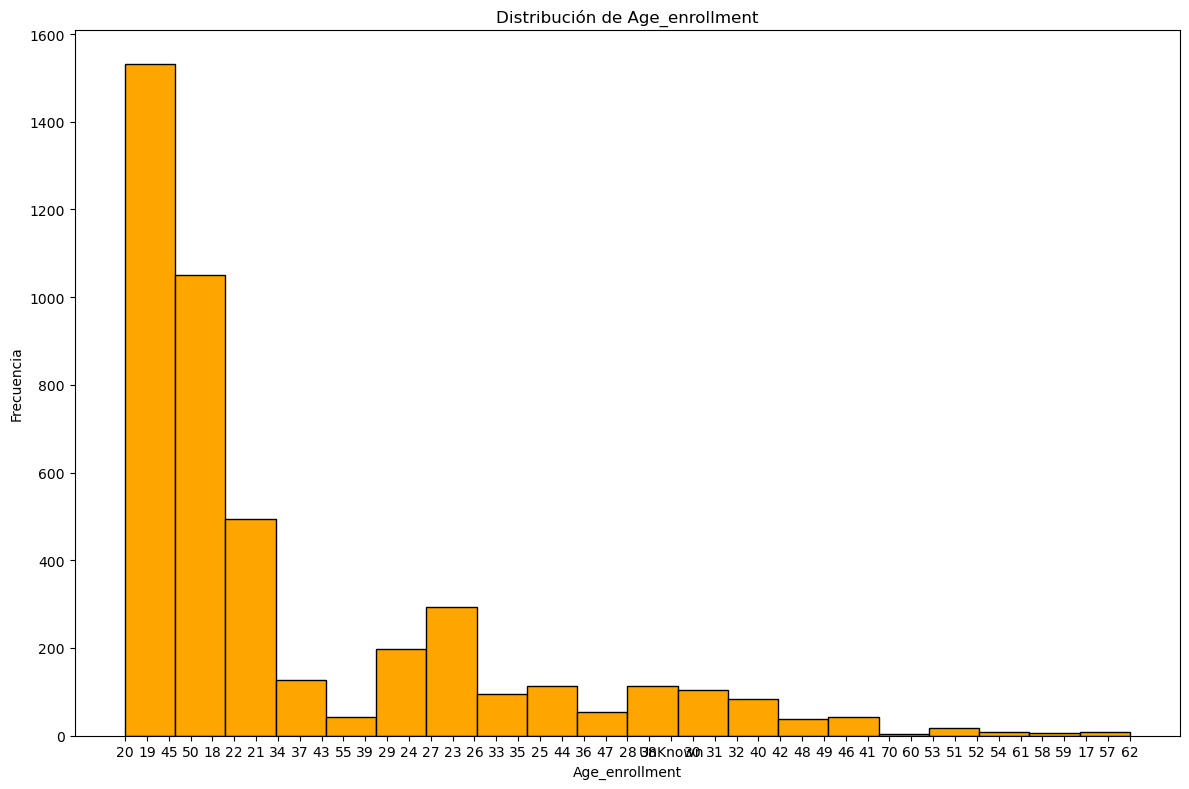

(array([4313.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,  110.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Intl')

Text(0.5, 0, 'Intl')

Text(0, 0.5, 'Frecuencia')

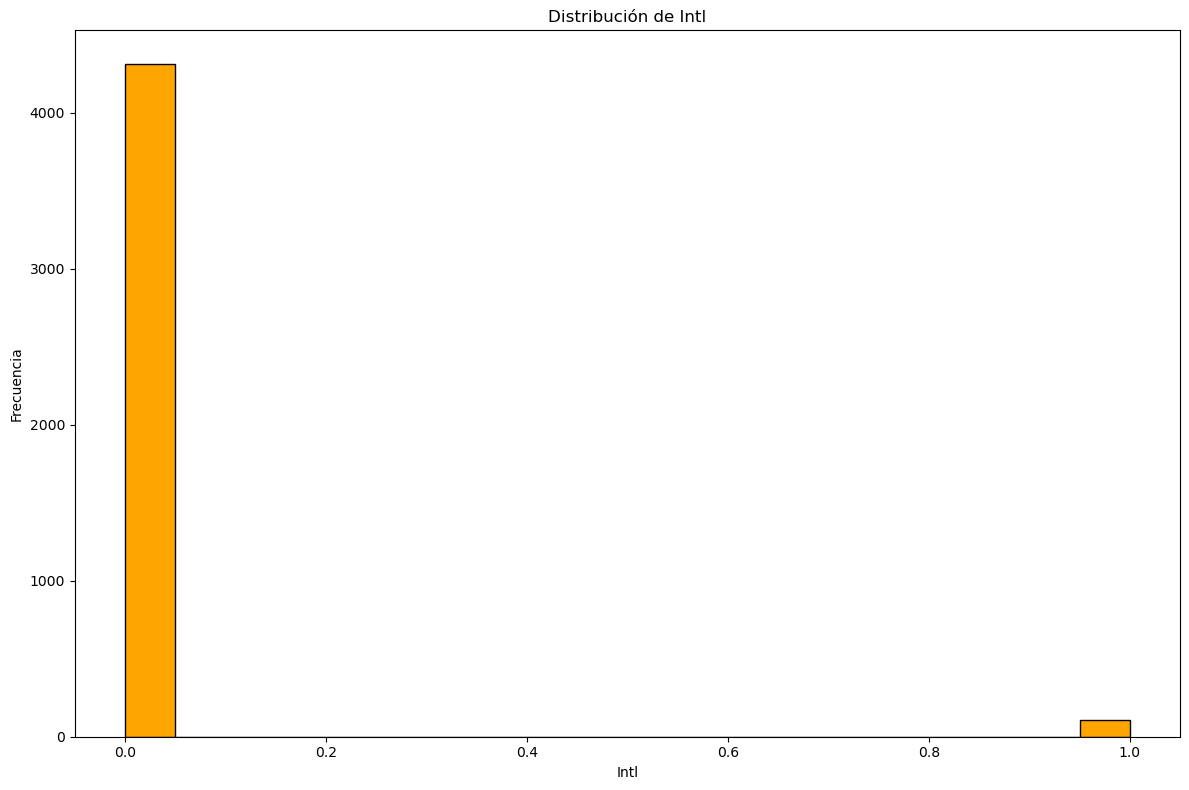

(array([3.941e+03, 6.900e+01, 5.000e+01, 4.100e+01, 1.300e+01, 4.700e+01,
        8.500e+01, 4.100e+01, 2.000e+00, 1.700e+01, 3.100e+01, 1.500e+01,
        2.700e+01, 5.000e+00, 1.200e+01, 1.500e+01, 4.000e+00, 3.000e+00,
        3.000e+00, 3.000e+00]),
 array([ 0.  ,  1.05,  2.1 ,  3.15,  4.2 ,  5.25,  6.3 ,  7.35,  8.4 ,
         9.45, 10.5 , 11.55, 12.6 , 13.65, 14.7 , 15.75, 16.8 , 17.85,
        18.9 , 19.95, 21.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_cred')

Text(0.5, 0, 'Curr_units_1sem_cred')

Text(0, 0.5, 'Frecuencia')

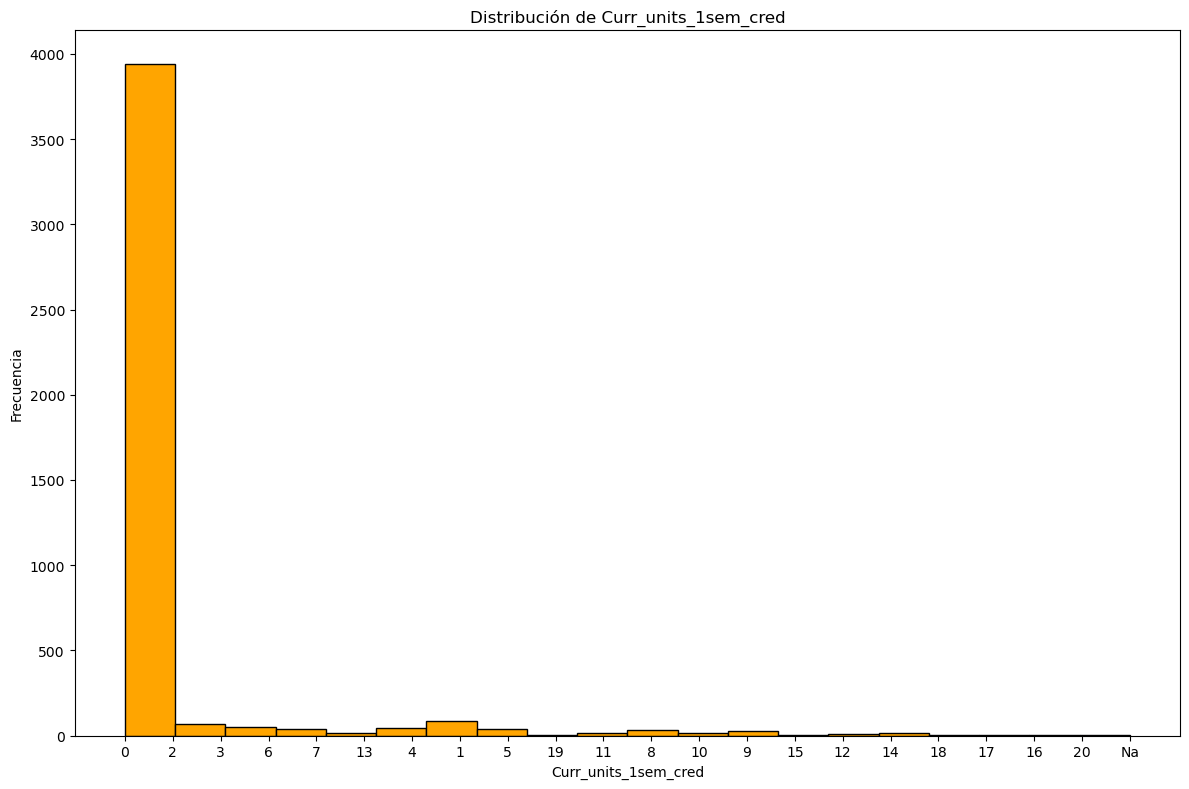

(array([1.870e+02, 9.000e+00, 1.000e+01, 1.031e+03, 1.910e+03, 6.560e+02,
        3.320e+02, 5.200e+01, 4.500e+01, 6.600e+01, 4.200e+01, 2.500e+01,
        1.300e+01, 3.500e+01, 2.000e+00, 0.000e+00, 6.000e+00, 2.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0. ,  1.3,  2.6,  3.9,  5.2,  6.5,  7.8,  9.1, 10.4, 11.7, 13. ,
        14.3, 15.6, 16.9, 18.2, 19.5, 20.8, 22.1, 23.4, 24.7, 26. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_enrol')

Text(0.5, 0, 'Curr_units_1sem_enrol')

Text(0, 0.5, 'Frecuencia')

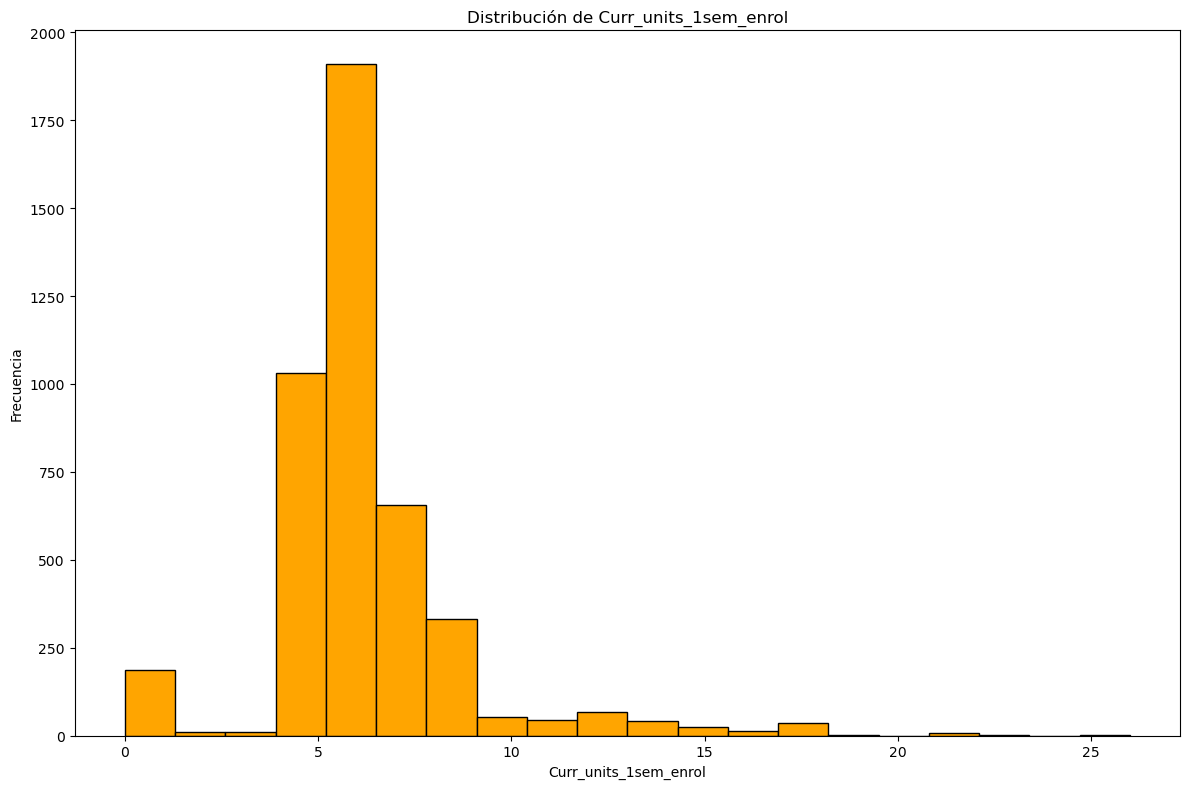

(array([3.630e+02, 2.500e+01, 8.180e+02, 1.494e+03, 9.810e+02, 3.630e+02,
        1.750e+02, 8.000e+01, 6.500e+01, 2.700e+01, 1.500e+01, 7.000e+00,
        5.000e+00, 1.000e+00, 2.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([ 0.  ,  2.25,  4.5 ,  6.75,  9.  , 11.25, 13.5 , 15.75, 18.  ,
        20.25, 22.5 , 24.75, 27.  , 29.25, 31.5 , 33.75, 36.  , 38.25,
        40.5 , 42.75, 45.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_eval')

Text(0.5, 0, 'Curr_units_1sem_eval')

Text(0, 0.5, 'Frecuencia')

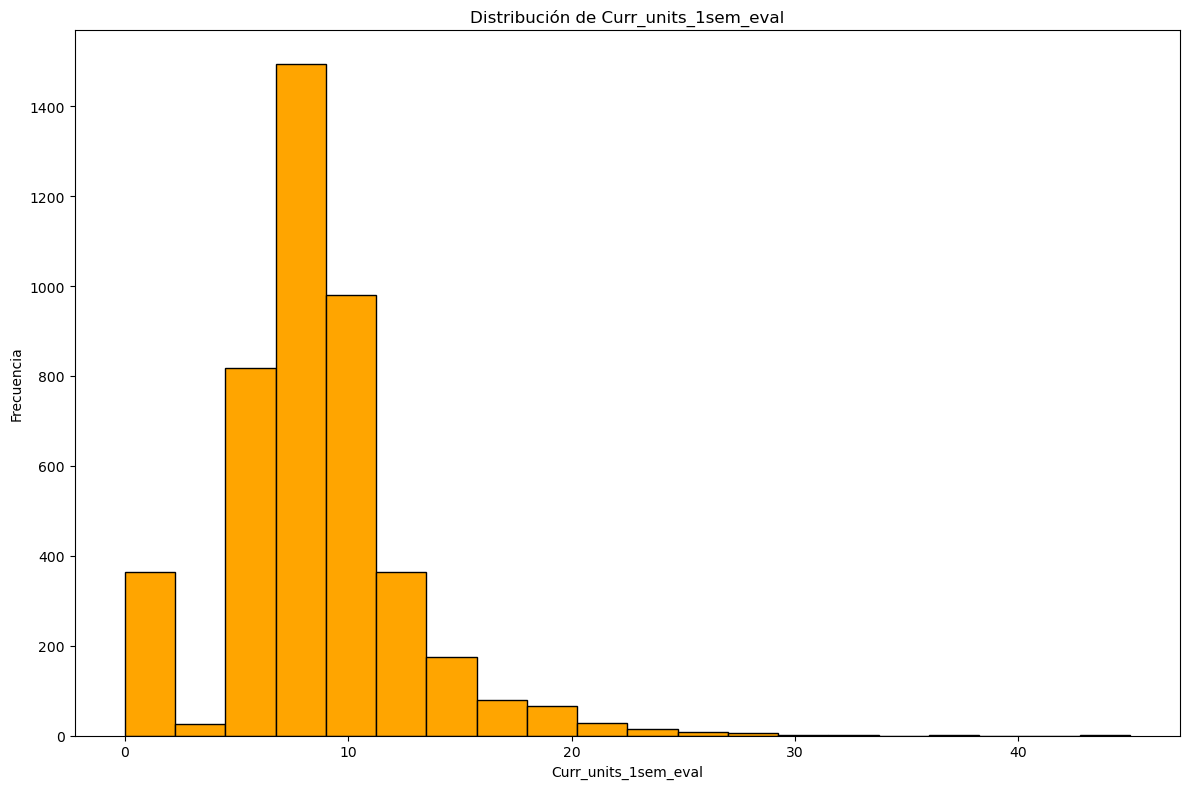

(array([8.450e+02, 1.600e+02, 2.690e+02, 1.156e+03, 1.171e+03, 4.710e+02,
        1.480e+02, 2.400e+01, 4.900e+01, 4.400e+01, 4.000e+01, 7.000e+00,
        5.000e+00, 2.500e+01, 2.000e+00, 3.000e+00, 4.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0. ,  1.3,  2.6,  3.9,  5.2,  6.5,  7.8,  9.1, 10.4, 11.7, 13. ,
        14.3, 15.6, 16.9, 18.2, 19.5, 20.8, 22.1, 23.4, 24.7, 26. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_appvd')

Text(0.5, 0, 'Curr_units_1sem_appvd')

Text(0, 0.5, 'Frecuencia')

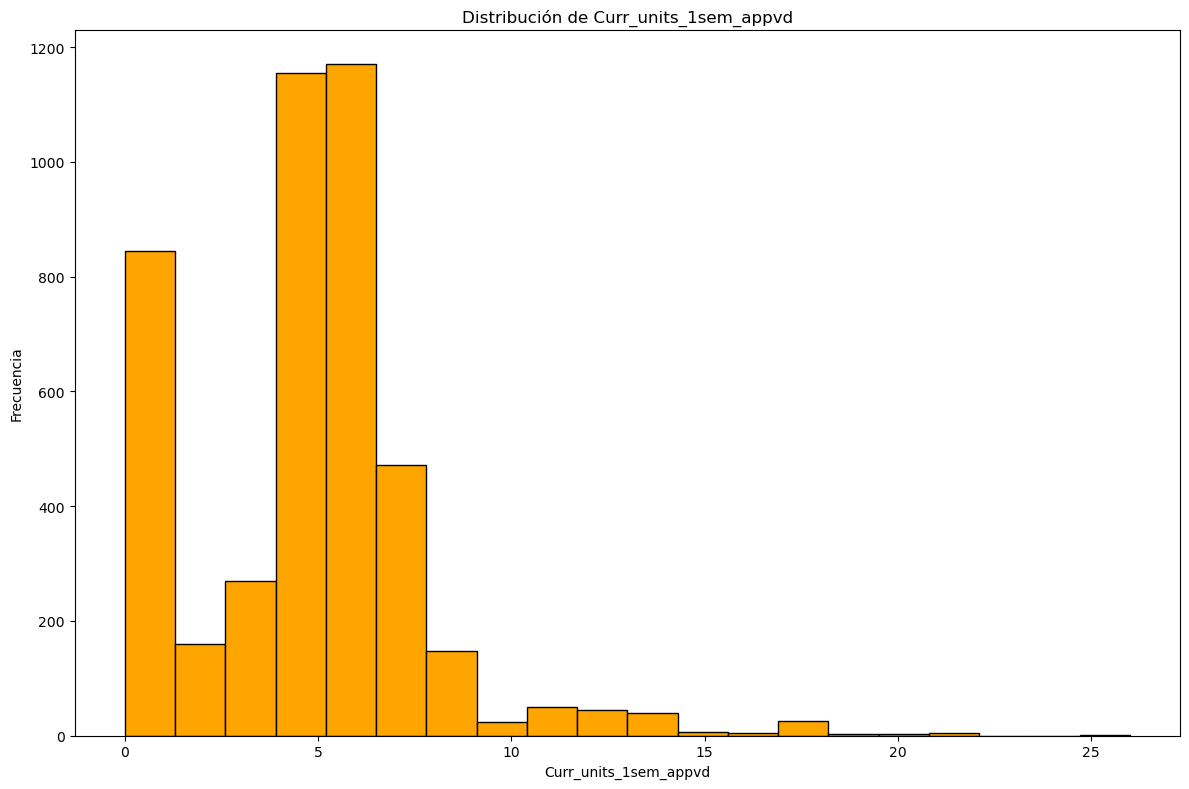

(array([718.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 120.,
        428., 929., 961., 737., 370., 119.,  28.,  10.,   3.]),
 array([ 0.     ,  0.94375,  1.8875 ,  2.83125,  3.775  ,  4.71875,
         5.6625 ,  6.60625,  7.55   ,  8.49375,  9.4375 , 10.38125,
        11.325  , 12.26875, 13.2125 , 14.15625, 15.1    , 16.04375,
        16.9875 , 17.93125, 18.875  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_grade')

Text(0.5, 0, 'Curr_units_1sem_grade')

Text(0, 0.5, 'Frecuencia')

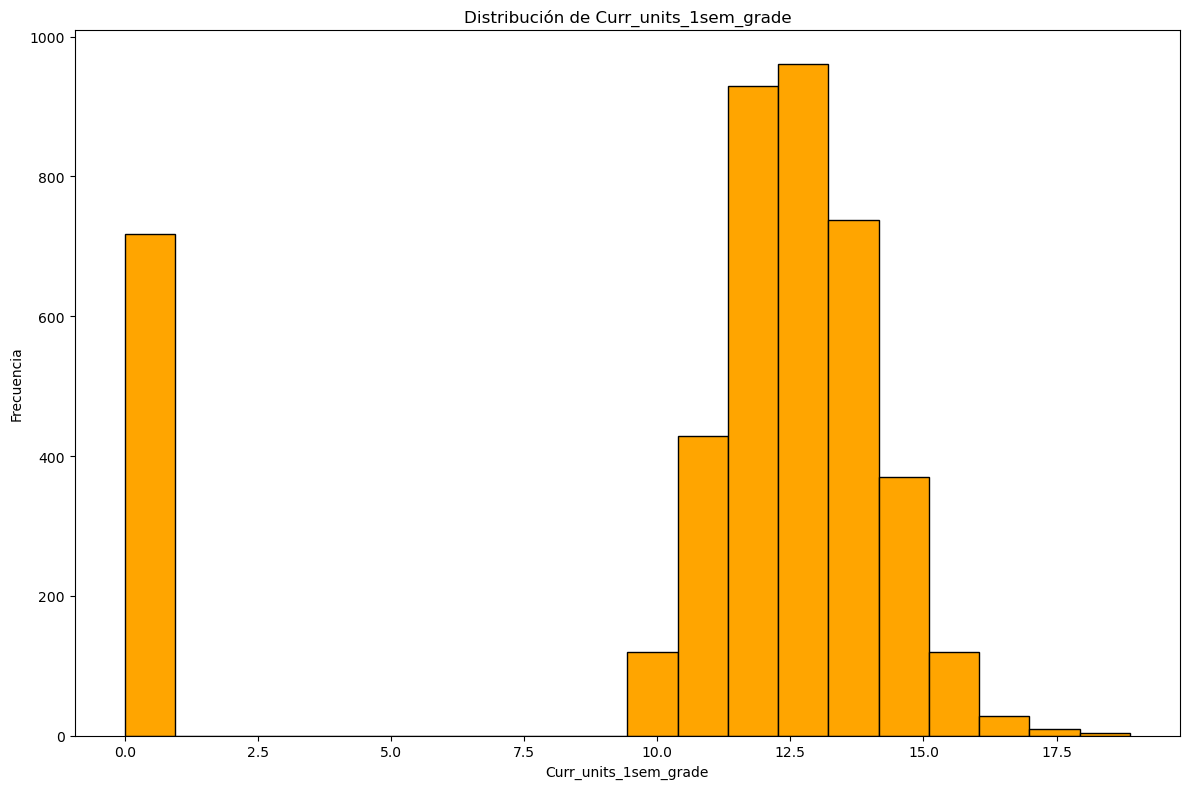

(array([4.13e+03, 1.53e+02, 0.00e+00, 7.90e+01, 0.00e+00, 2.30e+01,
        1.50e+01, 0.00e+00, 5.00e+00, 0.00e+00, 6.00e+00, 6.00e+00,
        0.00e+00, 4.00e+00, 0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00,
        0.00e+00, 2.00e+00]),
 array([ 0. ,  0.6,  1.2,  1.8,  2.4,  3. ,  3.6,  4.2,  4.8,  5.4,  6. ,
         6.6,  7.2,  7.8,  8.4,  9. ,  9.6, 10.2, 10.8, 11.4, 12. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_noeval')

Text(0.5, 0, 'Curr_units_1sem_noeval')

Text(0, 0.5, 'Frecuencia')

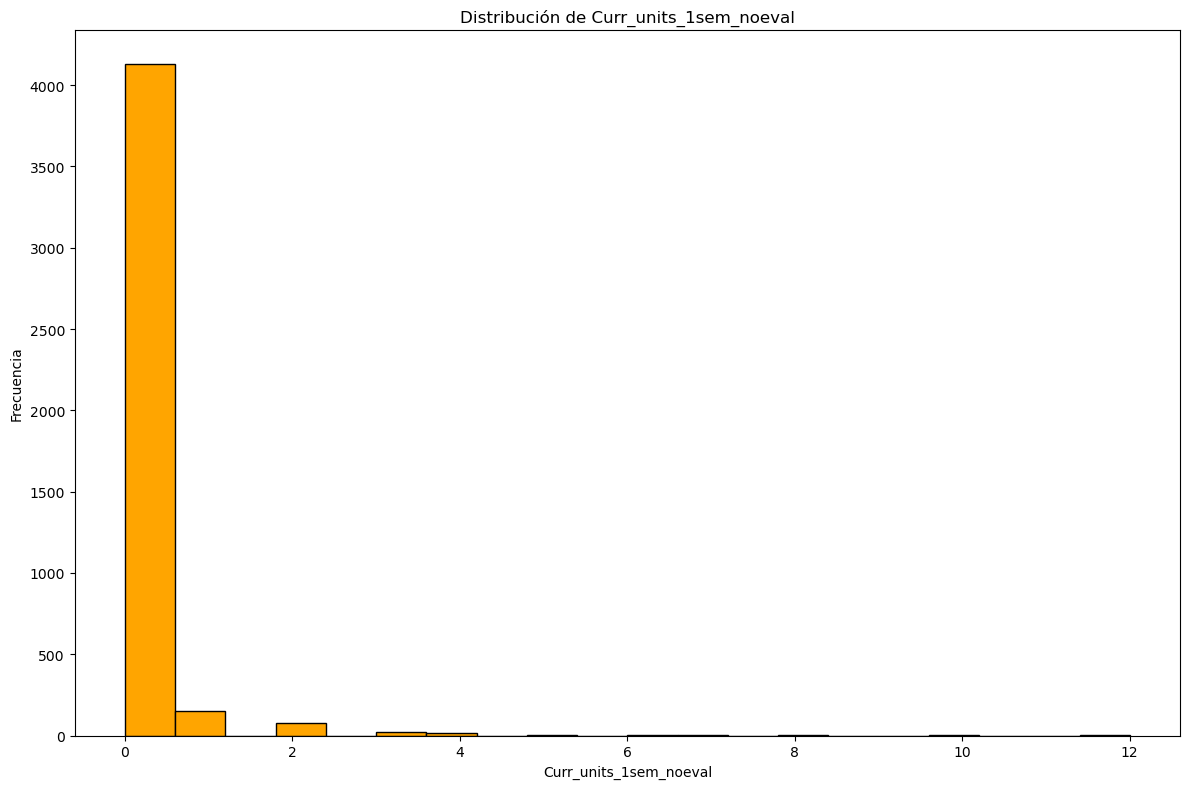

(array([3.894e+03, 1.070e+02, 9.200e+01, 4.900e+01, 7.800e+01, 6.800e+01,
        2.600e+01, 1.600e+01, 1.200e+01, 1.500e+01, 1.300e+01, 2.000e+01,
        1.400e+01, 9.000e+00, 4.000e+00, 2.000e+00, 2.000e+00, 0.000e+00,
        2.000e+00, 1.000e+00]),
 array([ 0.  ,  0.95,  1.9 ,  2.85,  3.8 ,  4.75,  5.7 ,  6.65,  7.6 ,
         8.55,  9.5 , 10.45, 11.4 , 12.35, 13.3 , 14.25, 15.2 , 16.15,
        17.1 , 18.05, 19.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_cred')

Text(0.5, 0, 'Curr_units_2sem_cred')

Text(0, 0.5, 'Frecuencia')

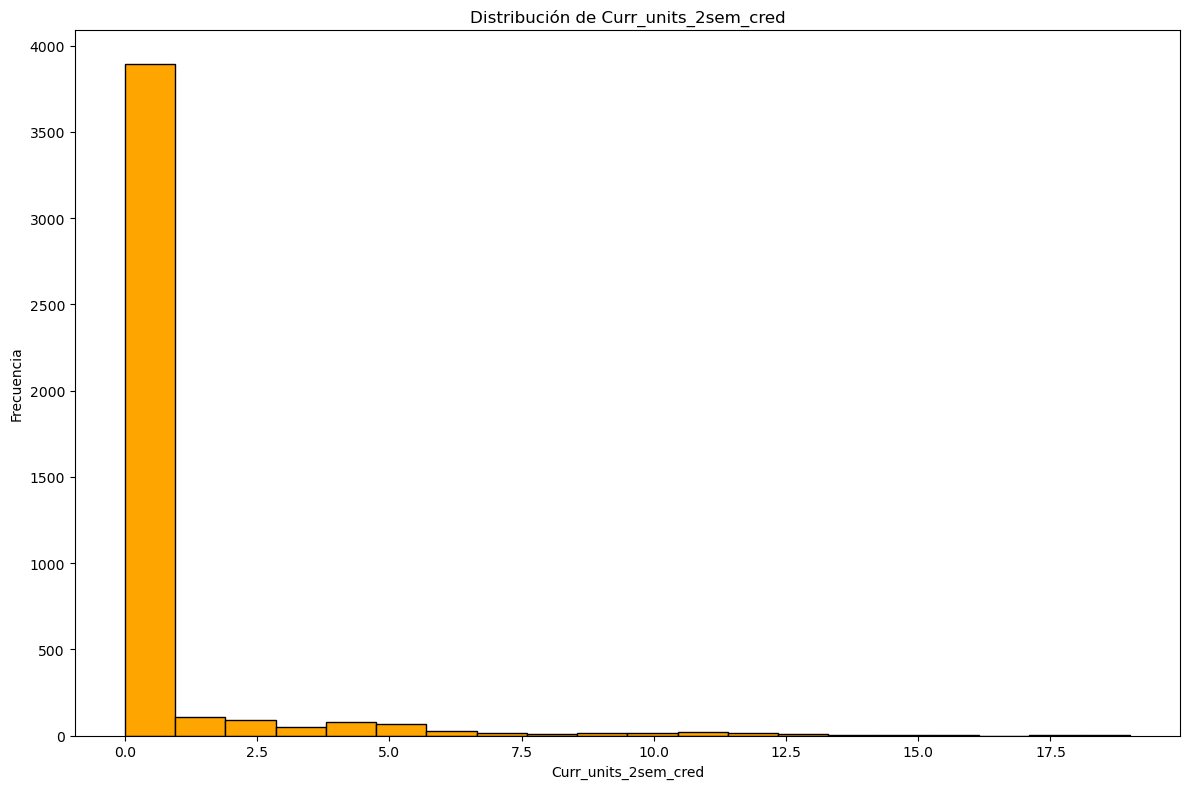

(array([1.830e+02, 5.000e+00, 3.000e+00, 1.700e+01, 1.054e+03, 1.913e+03,
        9.640e+02, 5.000e+01, 4.800e+01, 6.000e+01, 4.400e+01, 3.700e+01,
        2.200e+01, 3.000e+00, 1.200e+01, 2.000e+00, 3.000e+00, 0.000e+00,
        1.000e+00, 2.000e+00]),
 array([ 0.  ,  1.15,  2.3 ,  3.45,  4.6 ,  5.75,  6.9 ,  8.05,  9.2 ,
        10.35, 11.5 , 12.65, 13.8 , 14.95, 16.1 , 17.25, 18.4 , 19.55,
        20.7 , 21.85, 23.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_enrol')

Text(0.5, 0, 'Curr_units_2sem_enrol')

Text(0, 0.5, 'Frecuencia')

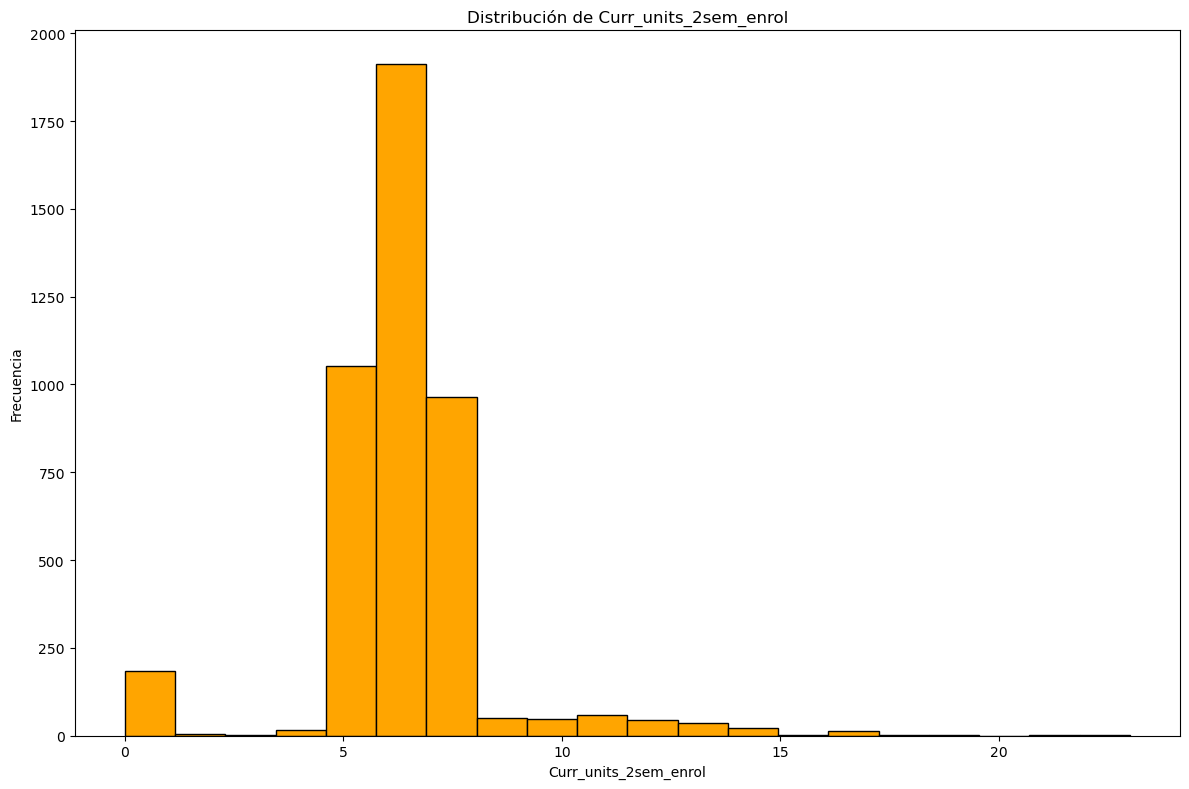

(array([4.040e+02, 6.000e+00, 1.000e+01, 9.020e+02, 1.355e+03, 4.560e+02,
        6.100e+02, 3.520e+02, 9.800e+01, 1.220e+02, 4.700e+01, 1.900e+01,
        1.800e+01, 1.400e+01, 3.000e+00, 4.000e+00, 3.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.  ,  1.65,  3.3 ,  4.95,  6.6 ,  8.25,  9.9 , 11.55, 13.2 ,
        14.85, 16.5 , 18.15, 19.8 , 21.45, 23.1 , 24.75, 26.4 , 28.05,
        29.7 , 31.35, 33.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_eval')

Text(0.5, 0, 'Curr_units_2sem_eval')

Text(0, 0.5, 'Frecuencia')

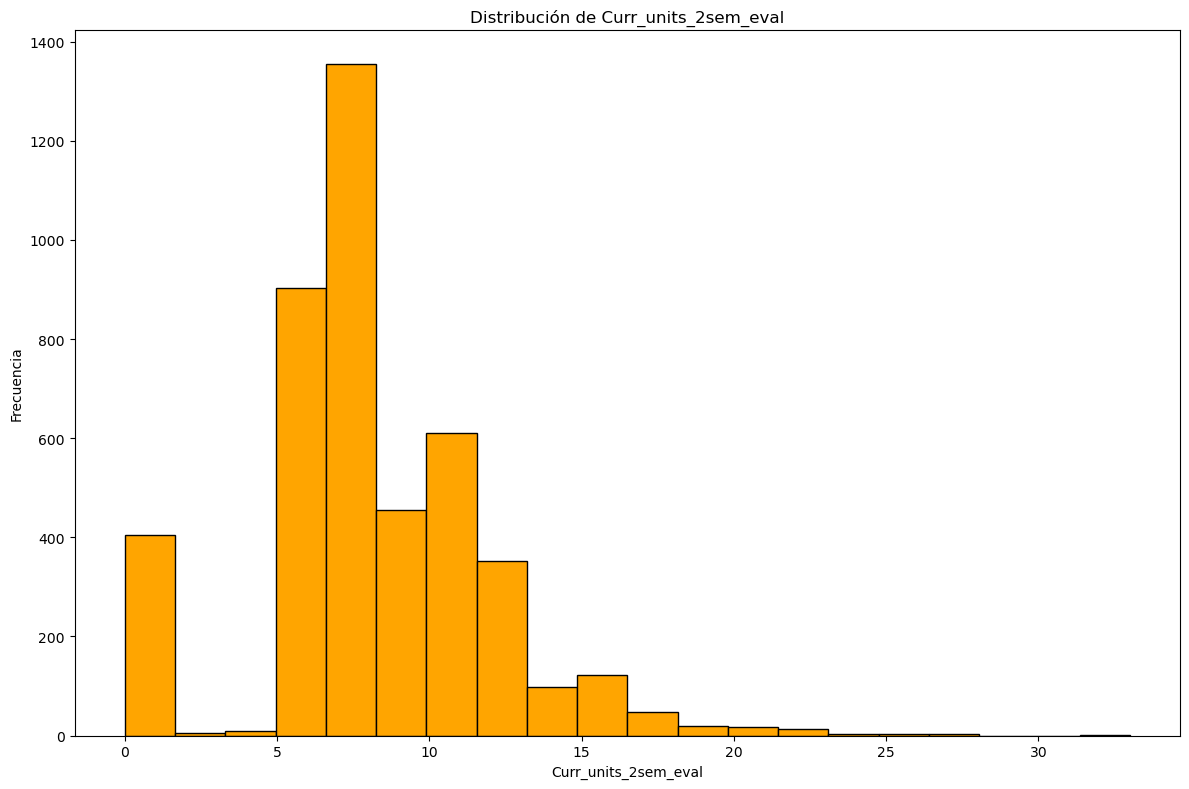

(array([870., 114., 198., 285., 414., 726., 965., 331., 321.,  36.,  38.,
         48.,  34.,  21.,   6.,   0.,   2.,   8.,   2.,   5.]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
        13., 14., 15., 16., 17., 18., 19., 20.]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_appvd')

Text(0.5, 0, 'Curr_units_2sem_appvd')

Text(0, 0.5, 'Frecuencia')

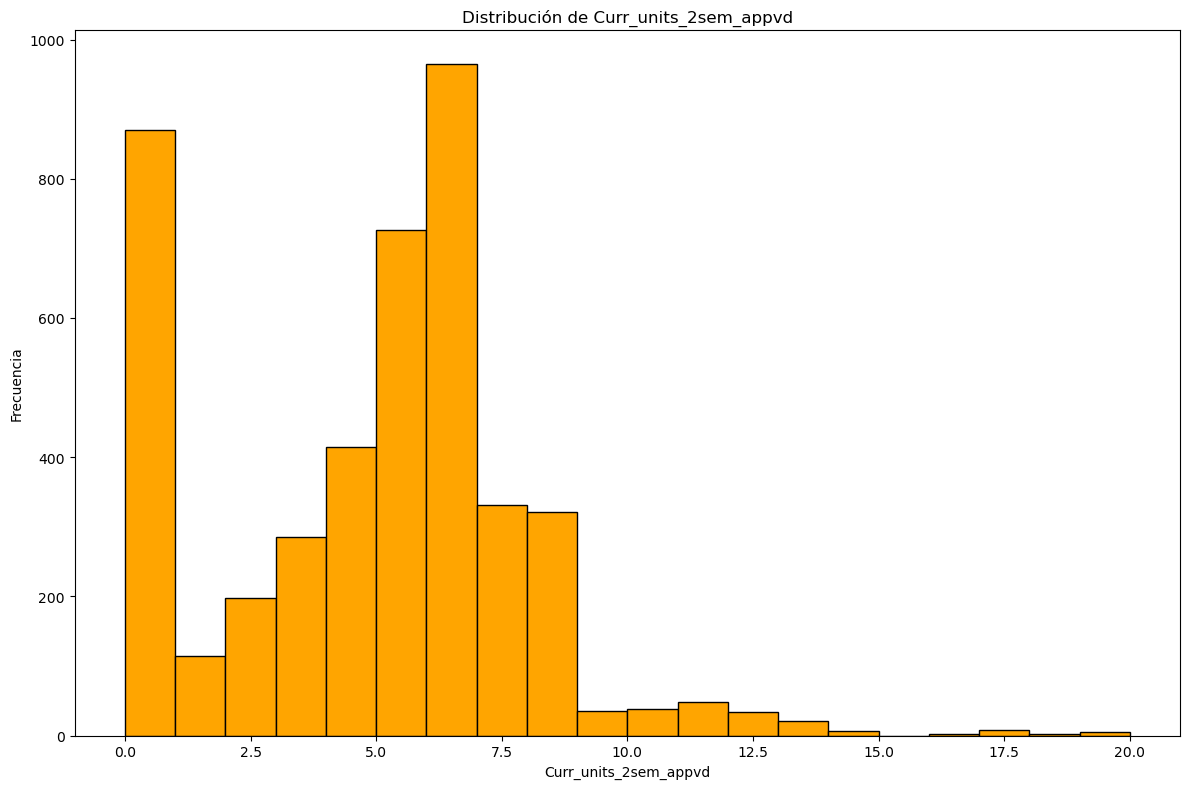

(array([870.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,  85.,
        357., 779., 816., 805., 464., 171.,  63.,  10.,   3.]),
 array([ 0.        ,  0.92857143,  1.85714286,  2.78571429,  3.71428571,
         4.64285714,  5.57142857,  6.5       ,  7.42857143,  8.35714286,
         9.28571429, 10.21428571, 11.14285714, 12.07142857, 13.        ,
        13.92857143, 14.85714286, 15.78571429, 16.71428571, 17.64285714,
        18.57142857]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_grade')

Text(0.5, 0, 'Curr_units_2sem_grade')

Text(0, 0.5, 'Frecuencia')

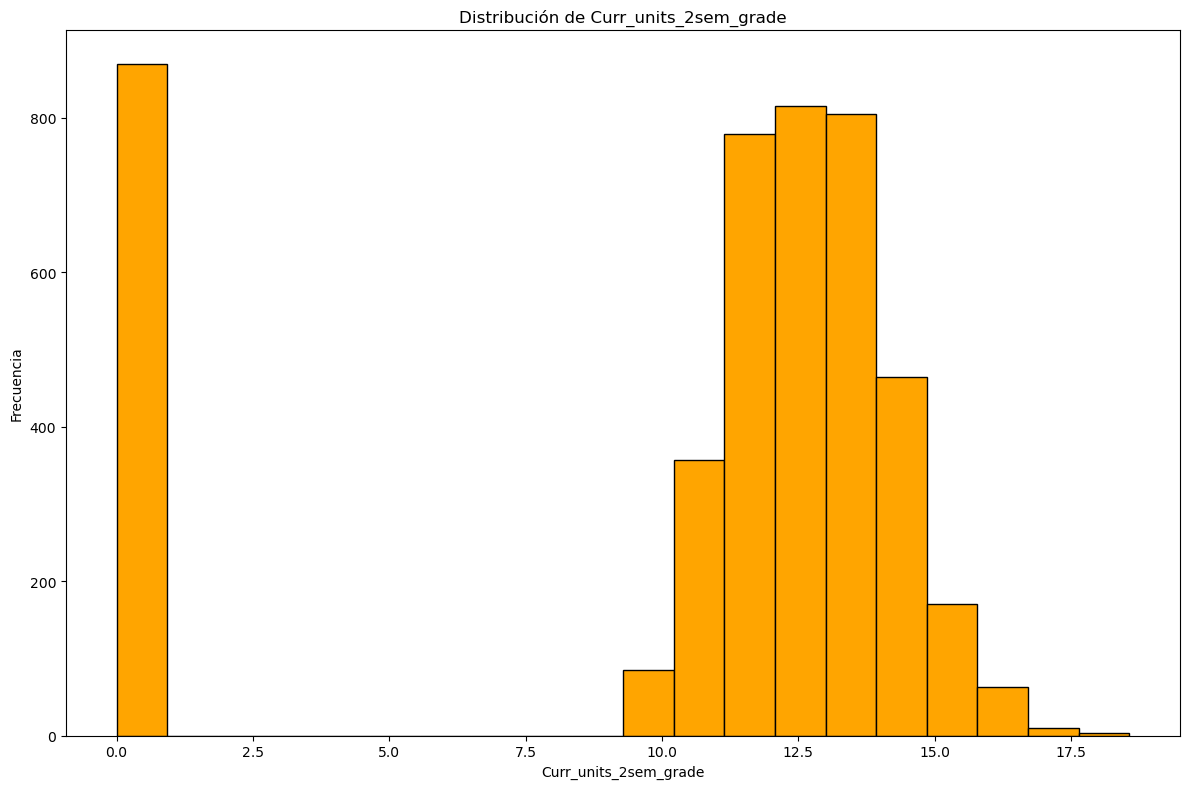

(array([4.142e+03, 1.400e+02, 0.000e+00, 4.800e+01, 0.000e+00, 3.500e+01,
        2.100e+01, 0.000e+00, 1.700e+01, 0.000e+00, 8.000e+00, 5.000e+00,
        0.000e+00, 6.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([ 0. ,  0.6,  1.2,  1.8,  2.4,  3. ,  3.6,  4.2,  4.8,  5.4,  6. ,
         6.6,  7.2,  7.8,  8.4,  9. ,  9.6, 10.2, 10.8, 11.4, 12. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_noevaluat')

Text(0.5, 0, 'Curr_units_2sem_noevaluat')

Text(0, 0.5, 'Frecuencia')

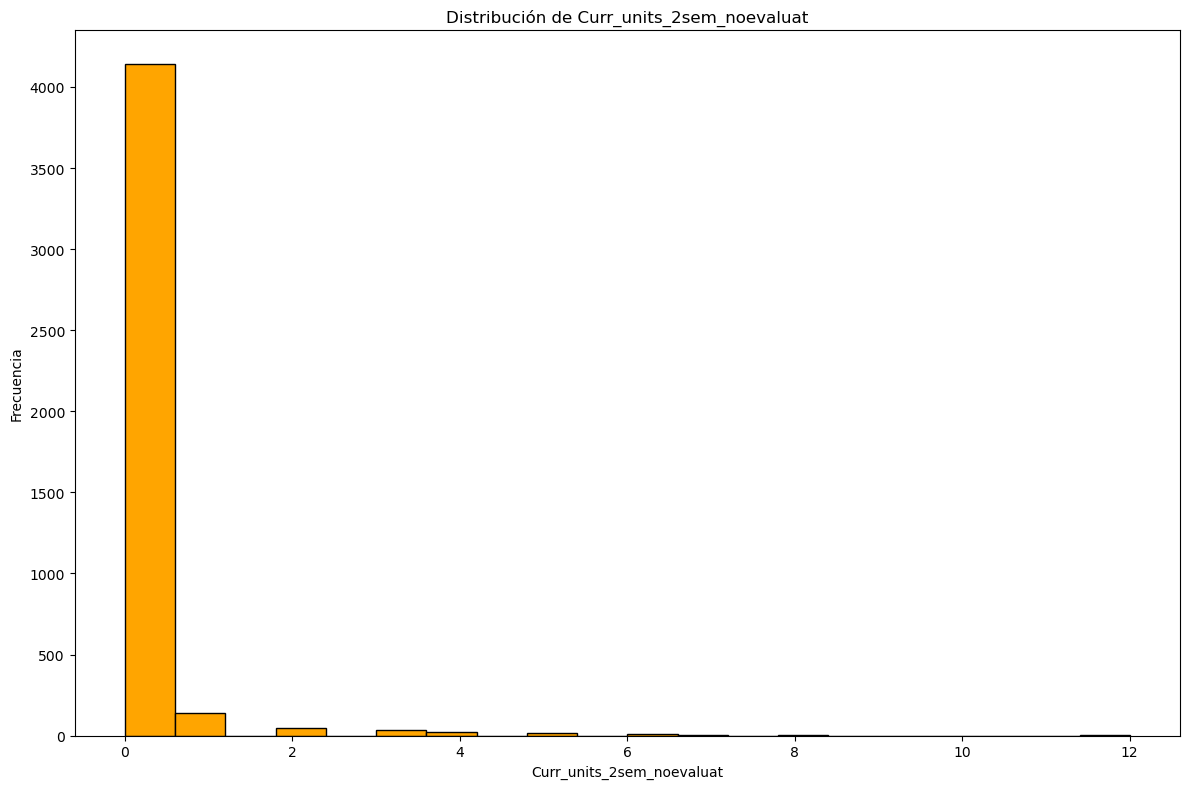

In [148]:
#Integer columns
integ_col = ['Marital_status', 'Appl_mode', 'Appl_order', 'Course', 'Day/evening attend', 'Prev_qualif_grade', 'Nationality',
            "Mother's_qualif", "Father's_qualif", "Mother's_occup", "Father's_occup", 'Displaced', 'Educ_special_needs',
            'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder', 'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
            'Curr_units_1sem_enrol', 'Curr_units_1sem_eval', 'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
            'Curr_units_1sem_noeval', 'Curr_units_2sem_cred', 'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
            'Curr_units_2sem_appvd', 'Curr_units_2sem_grade', 'Curr_units_2sem_noevaluat']

df_clean[integ_col] = df_clean[integ_col].apply(pd.to_numeric, errors="coerce")

for i in integ_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Graficar histograma
    ax.hist(df[i].dropna(), bins=20, color='orange', edgecolor='black')
    
    ax.set_title(f'Distribución de {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frecuencia')
    
    plt.tight_layout()
    plt.show()

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Marital_status'>

Text(0.5, 1.0, 'Boxplot of Marital_status')

Text(0.5, 0, 'Marital_status')

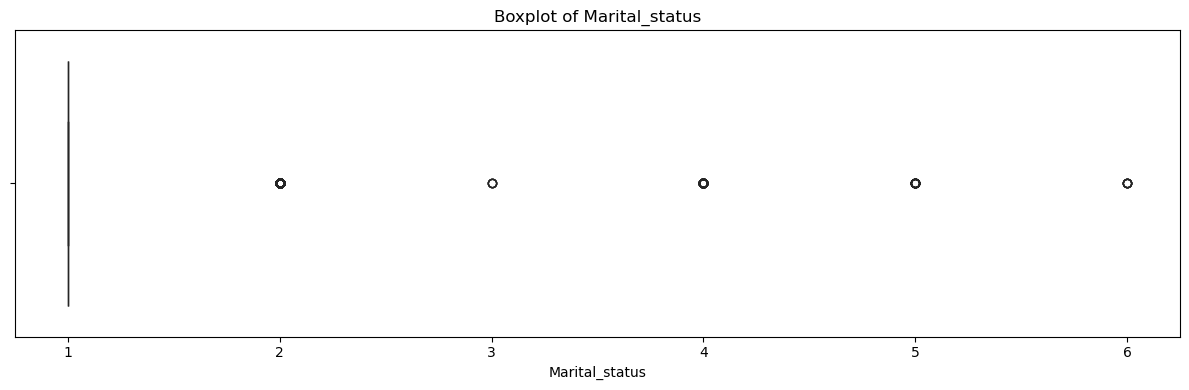

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Appl_mode'>

Text(0.5, 1.0, 'Boxplot of Appl_mode')

Text(0.5, 0, 'Appl_mode')

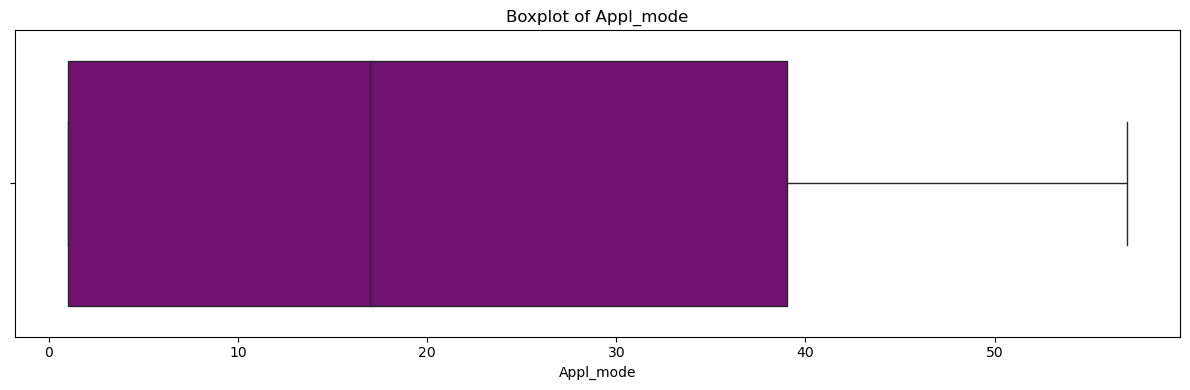

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Appl_order'>

Text(0.5, 1.0, 'Boxplot of Appl_order')

Text(0.5, 0, 'Appl_order')

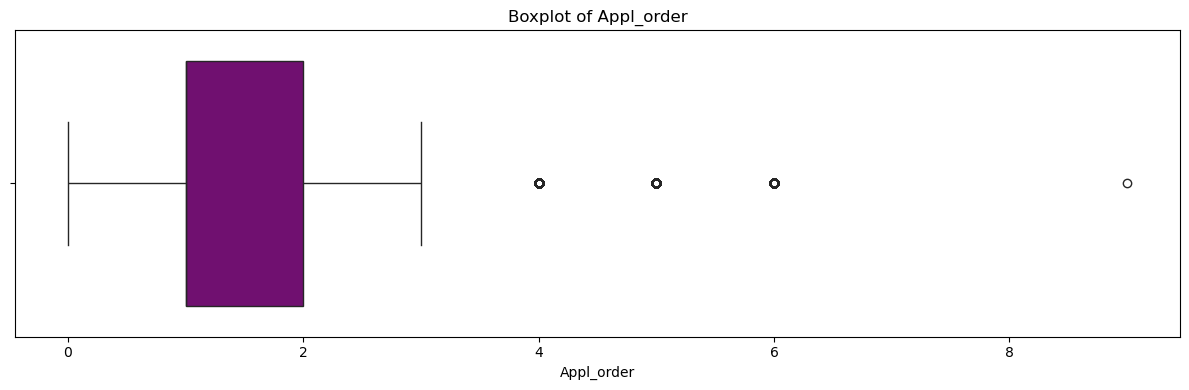

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Course'>

Text(0.5, 1.0, 'Boxplot of Course')

Text(0.5, 0, 'Course')

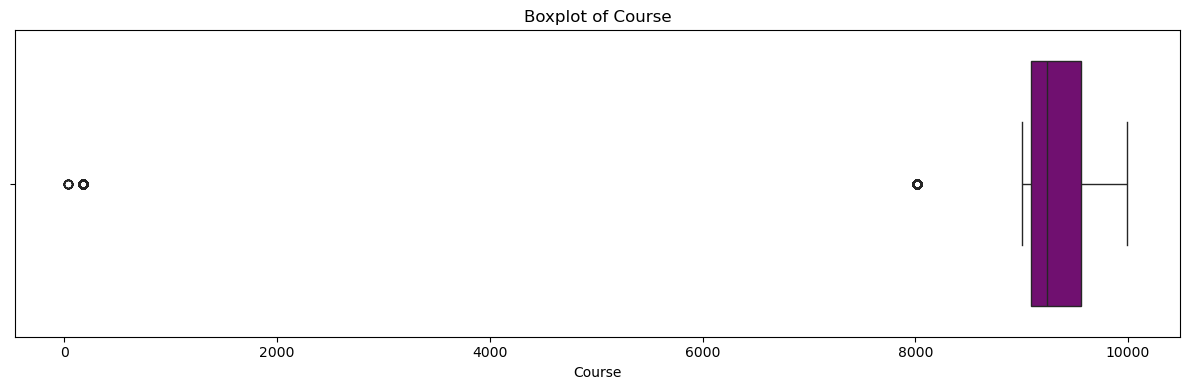

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Day/evening attend'>

Text(0.5, 1.0, 'Boxplot of Day/evening attend')

Text(0.5, 0, 'Day/evening attend')

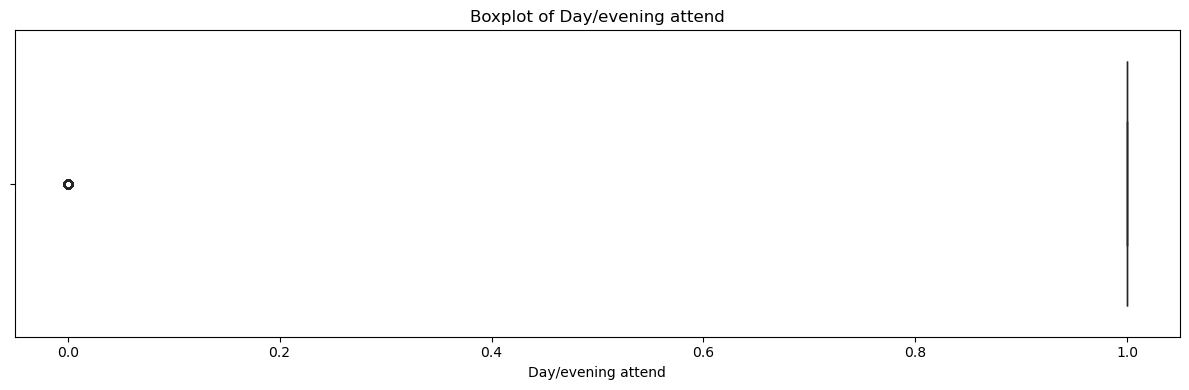

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Prev_qualif_grade'>

Text(0.5, 1.0, 'Boxplot of Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

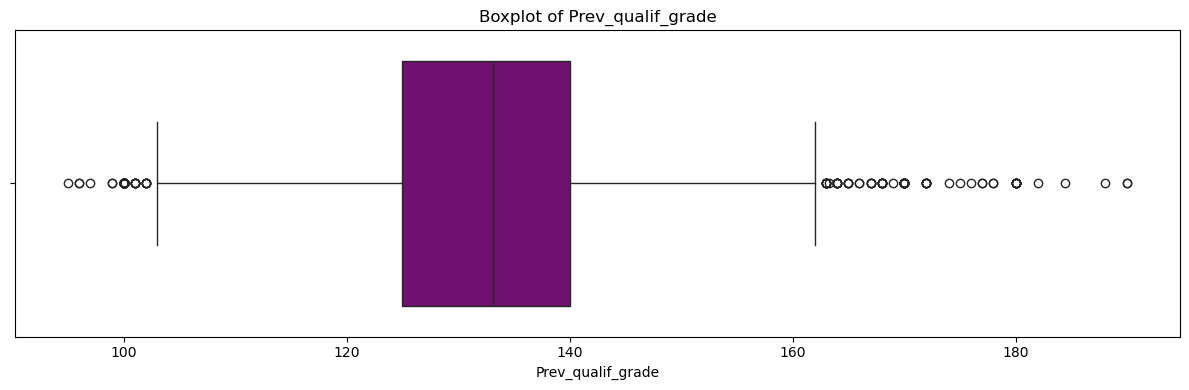

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Nationality'>

Text(0.5, 1.0, 'Boxplot of Nationality')

Text(0.5, 0, 'Nationality')

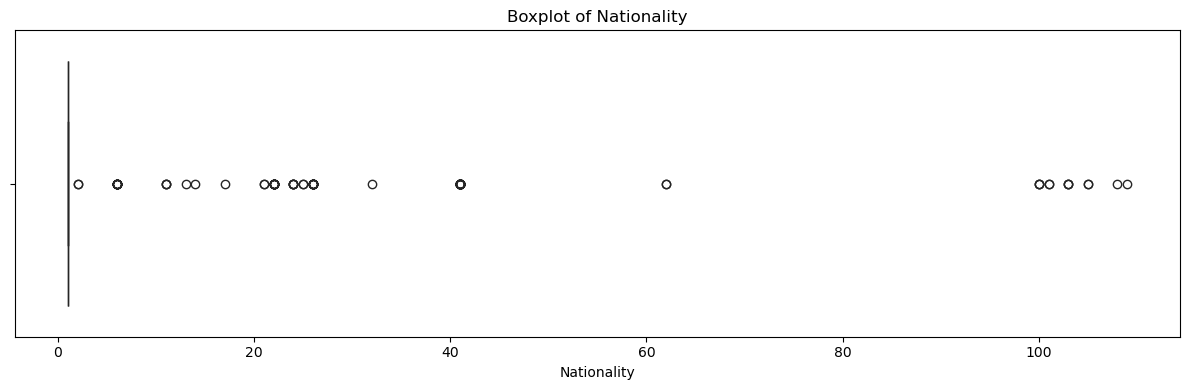

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Mother's_qualif">

Text(0.5, 1.0, "Boxplot of Mother's_qualif")

Text(0.5, 0, "Mother's_qualif")

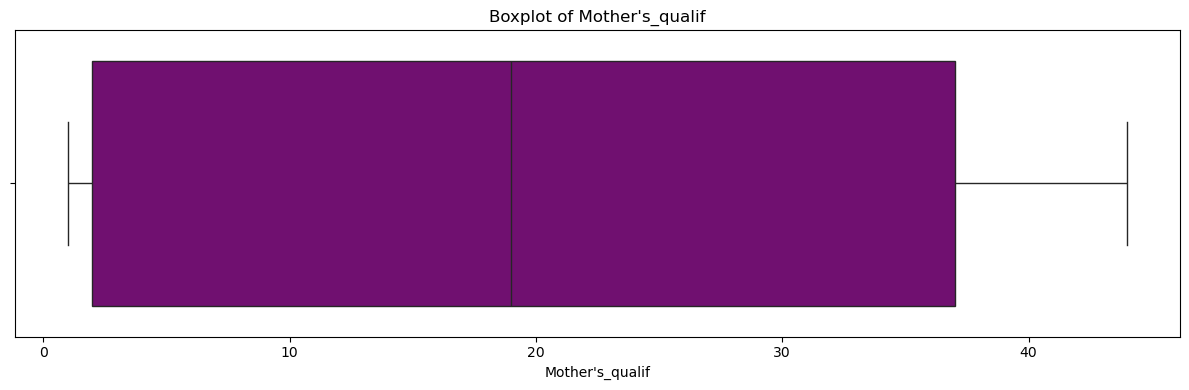

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Father's_qualif">

Text(0.5, 1.0, "Boxplot of Father's_qualif")

Text(0.5, 0, "Father's_qualif")

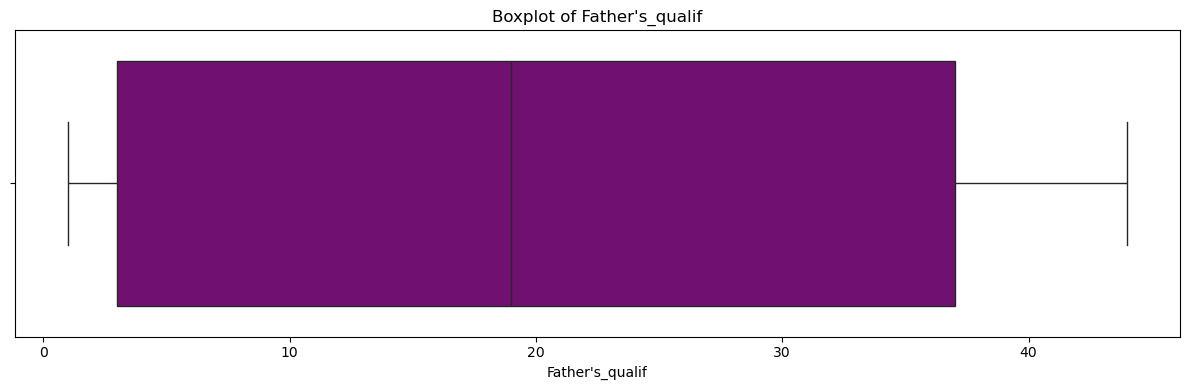

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Mother's_occup">

Text(0.5, 1.0, "Boxplot of Mother's_occup")

Text(0.5, 0, "Mother's_occup")

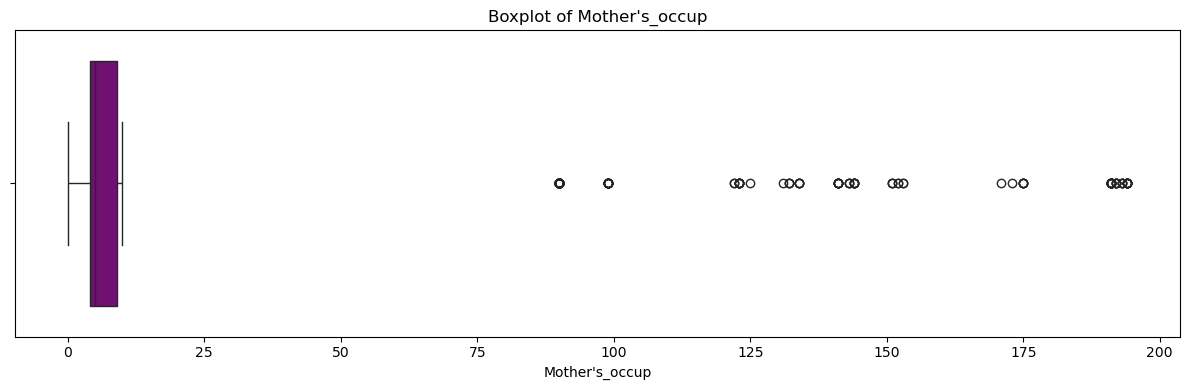

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Father's_occup">

Text(0.5, 1.0, "Boxplot of Father's_occup")

Text(0.5, 0, "Father's_occup")

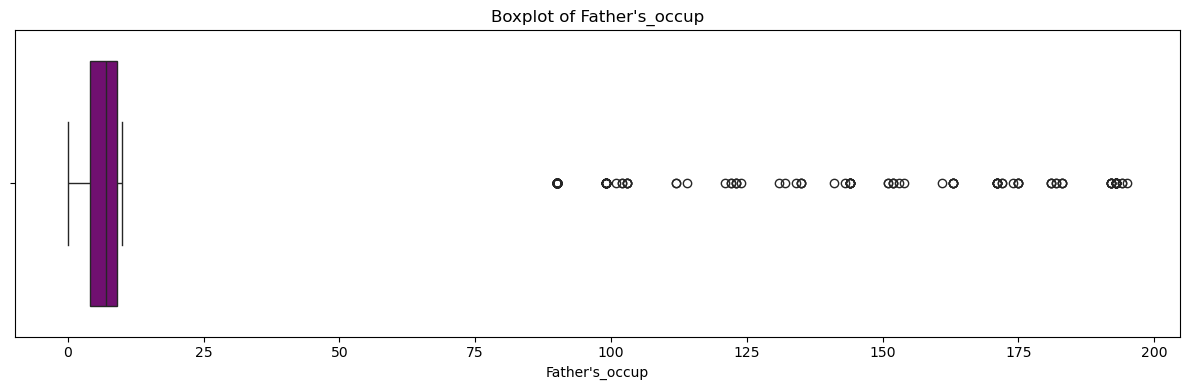

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Displaced'>

Text(0.5, 1.0, 'Boxplot of Displaced')

Text(0.5, 0, 'Displaced')

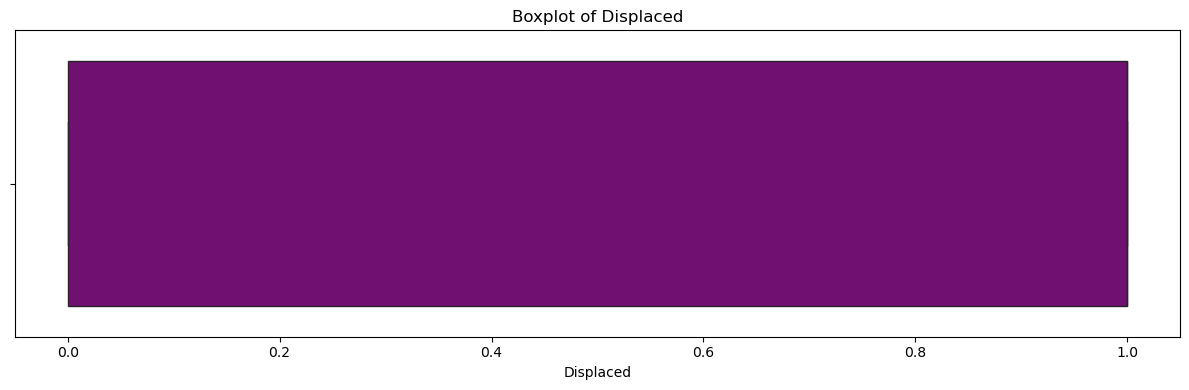

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Educ_special_needs'>

Text(0.5, 1.0, 'Boxplot of Educ_special_needs')

Text(0.5, 0, 'Educ_special_needs')

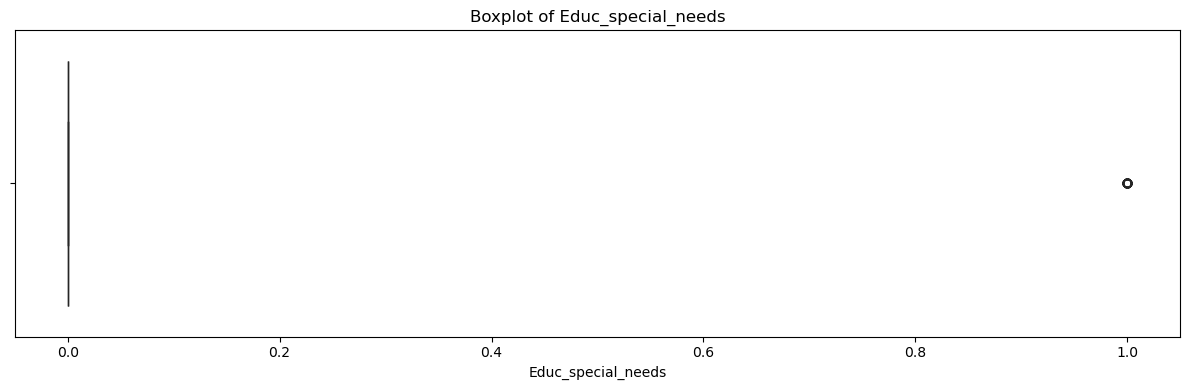

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Debtor'>

Text(0.5, 1.0, 'Boxplot of Debtor')

Text(0.5, 0, 'Debtor')

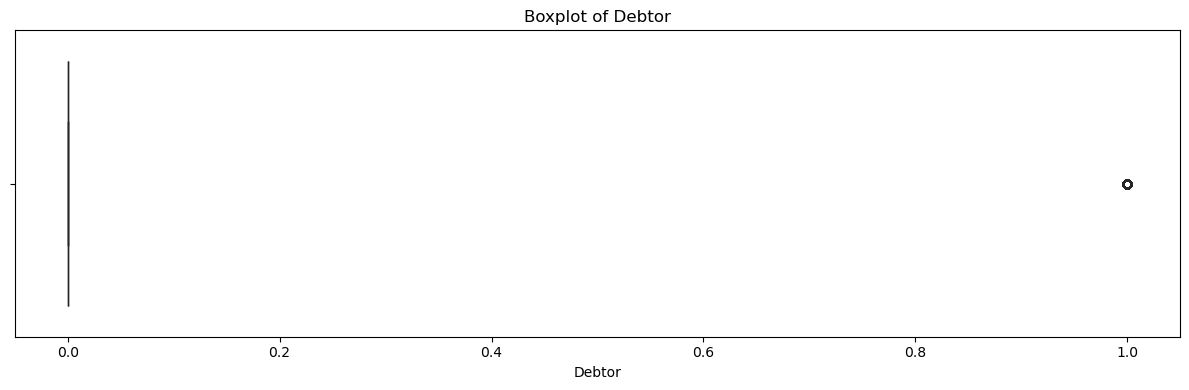

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Tuit_fees_upto_date'>

Text(0.5, 1.0, 'Boxplot of Tuit_fees_upto_date')

Text(0.5, 0, 'Tuit_fees_upto_date')

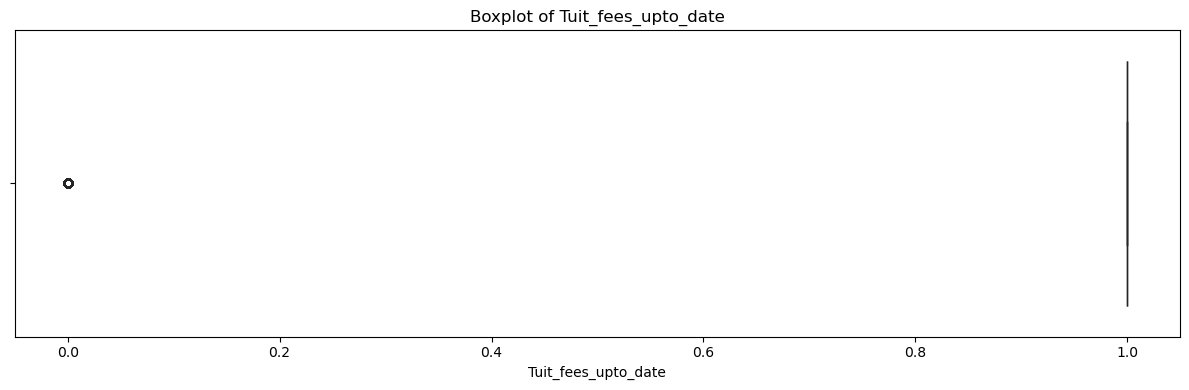

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Gender'>

Text(0.5, 1.0, 'Boxplot of Gender')

Text(0.5, 0, 'Gender')

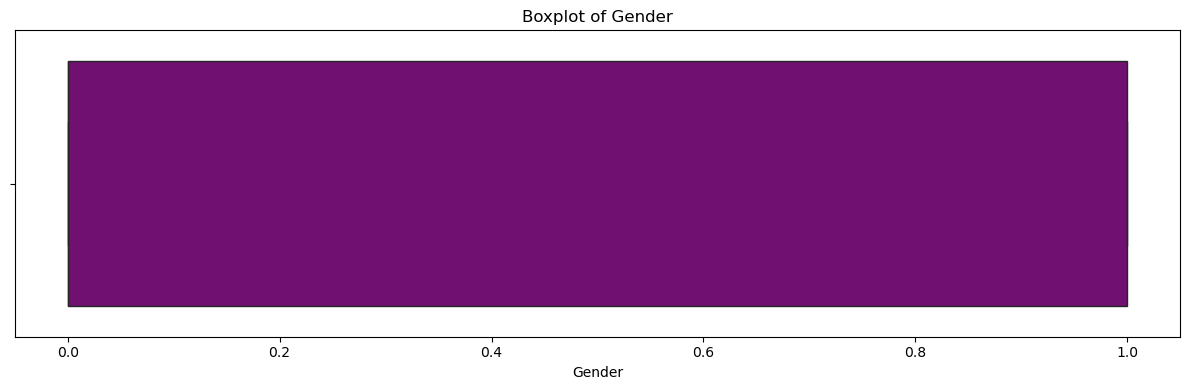

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Scholar_holder'>

Text(0.5, 1.0, 'Boxplot of Scholar_holder')

Text(0.5, 0, 'Scholar_holder')

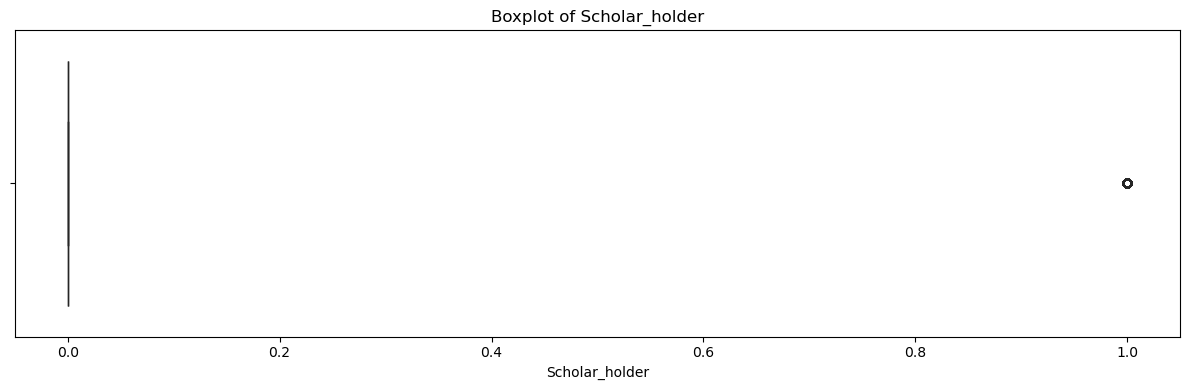

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Age_enrollment'>

Text(0.5, 1.0, 'Boxplot of Age_enrollment')

Text(0.5, 0, 'Age_enrollment')

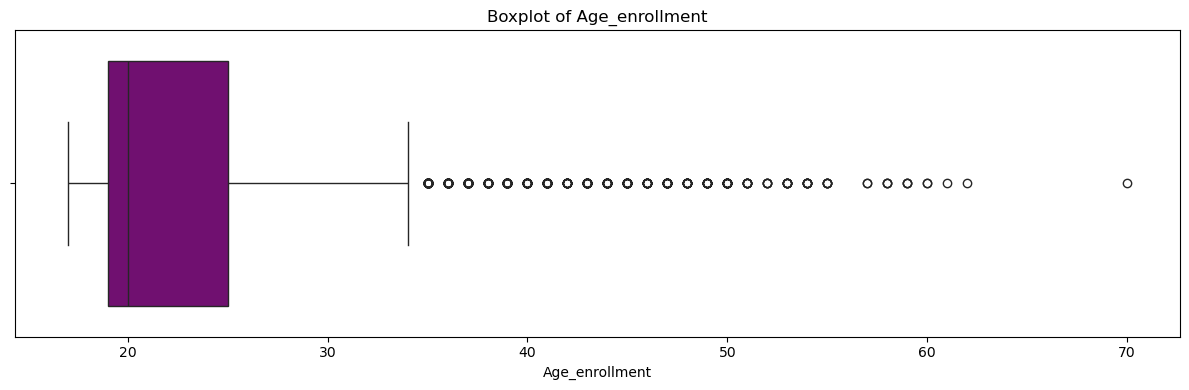

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Intl'>

Text(0.5, 1.0, 'Boxplot of Intl')

Text(0.5, 0, 'Intl')

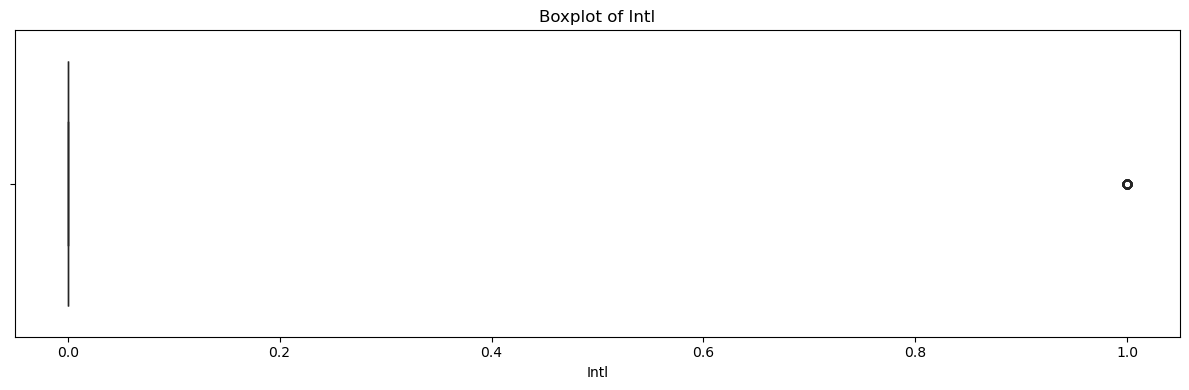

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_cred'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_cred')

Text(0.5, 0, 'Curr_units_1sem_cred')

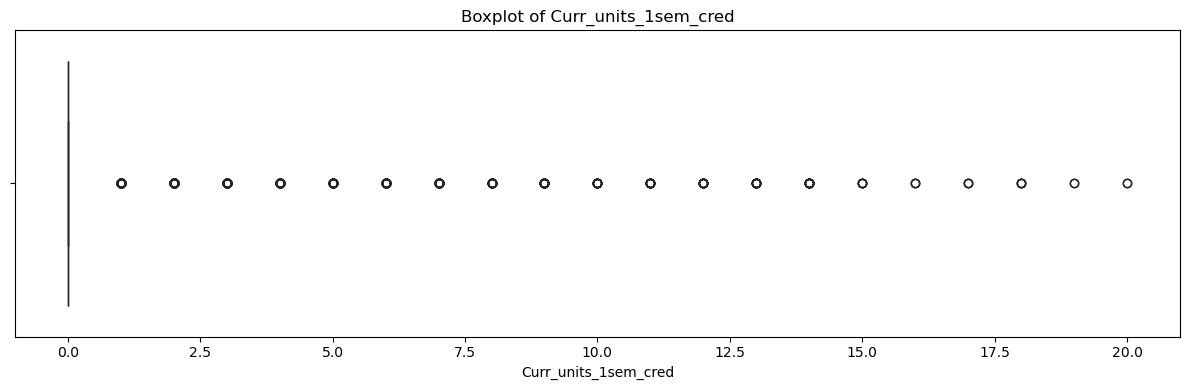

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_enrol'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_enrol')

Text(0.5, 0, 'Curr_units_1sem_enrol')

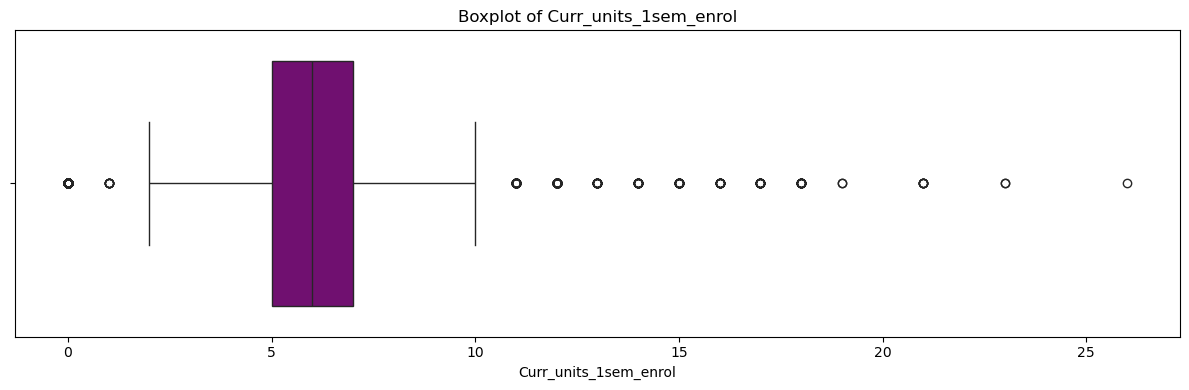

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_eval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_eval')

Text(0.5, 0, 'Curr_units_1sem_eval')

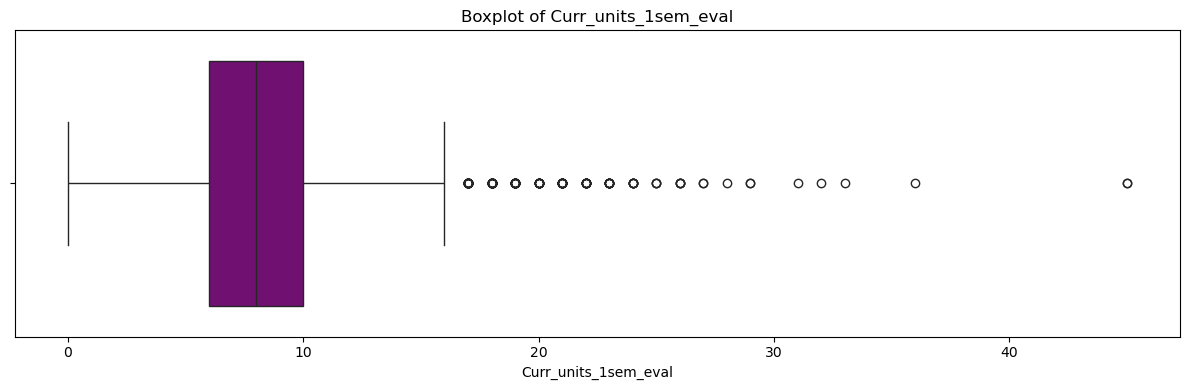

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_appvd'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_appvd')

Text(0.5, 0, 'Curr_units_1sem_appvd')

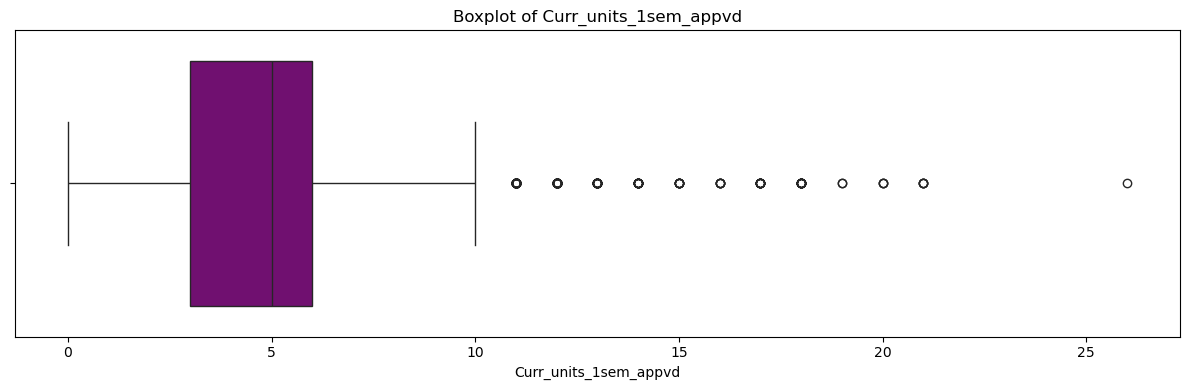

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_grade'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_grade')

Text(0.5, 0, 'Curr_units_1sem_grade')

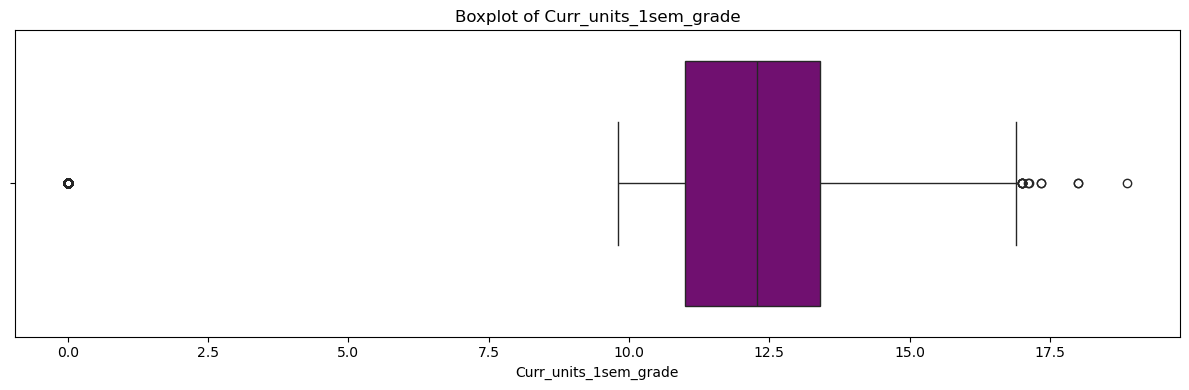

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_noeval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_noeval')

Text(0.5, 0, 'Curr_units_1sem_noeval')

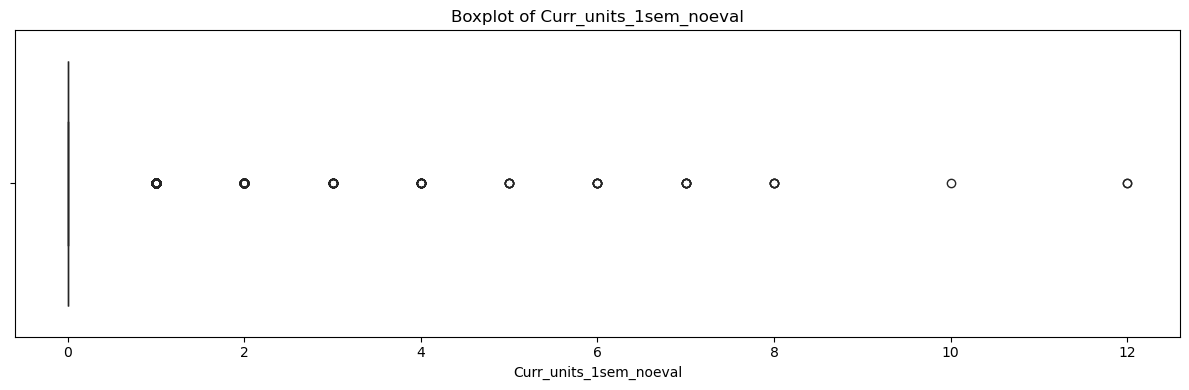

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_cred'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_cred')

Text(0.5, 0, 'Curr_units_2sem_cred')

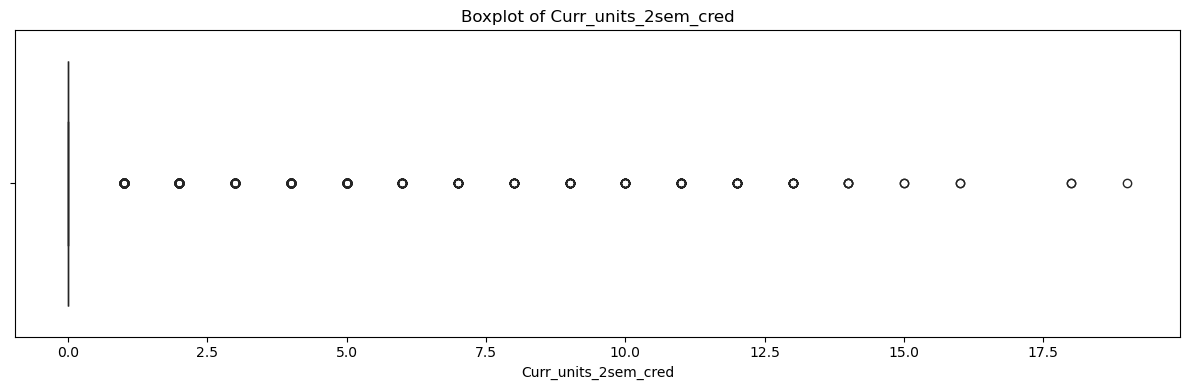

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_enrol'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_enrol')

Text(0.5, 0, 'Curr_units_2sem_enrol')

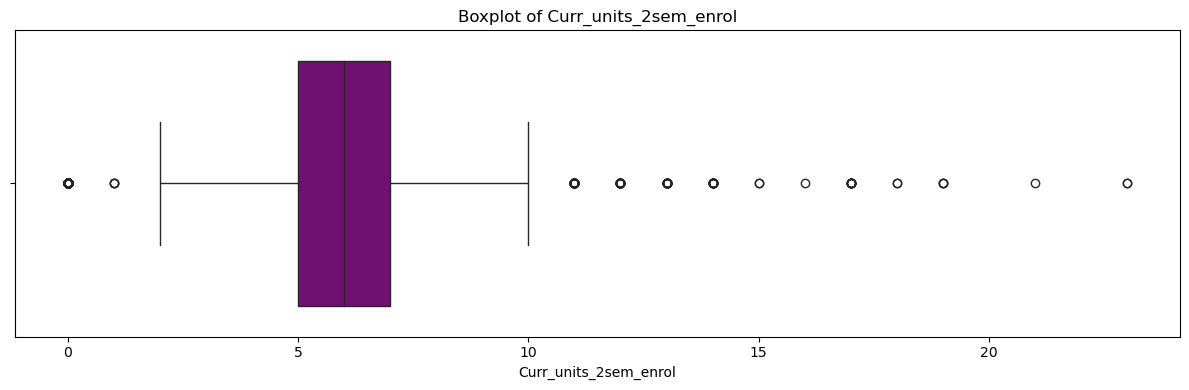

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_eval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_eval')

Text(0.5, 0, 'Curr_units_2sem_eval')

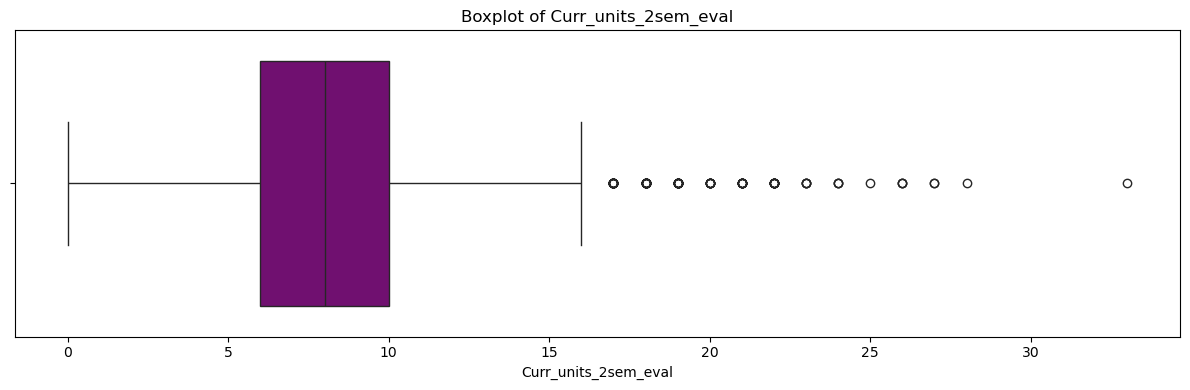

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_appvd'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_appvd')

Text(0.5, 0, 'Curr_units_2sem_appvd')

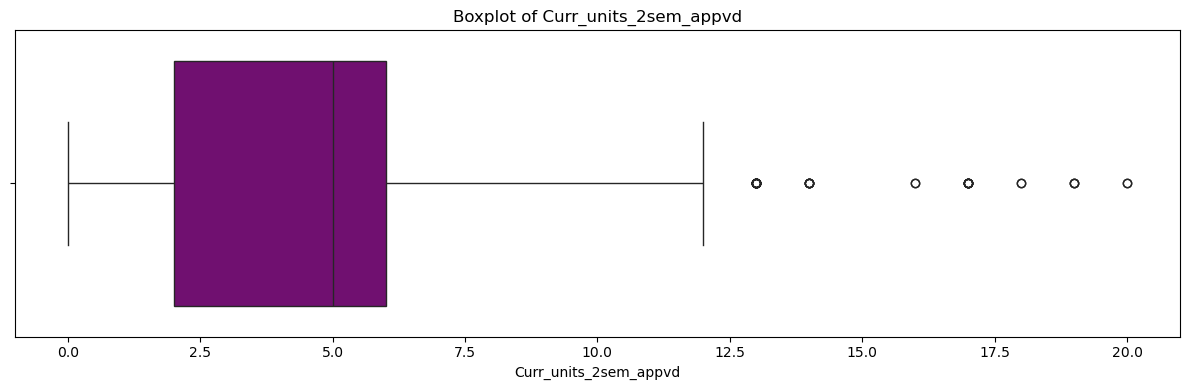

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_grade'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_grade')

Text(0.5, 0, 'Curr_units_2sem_grade')

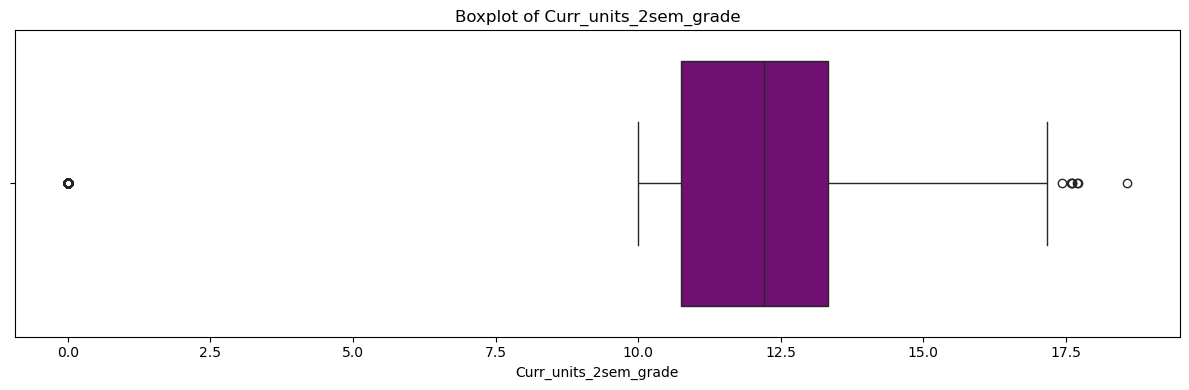

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_noevaluat'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_noevaluat')

Text(0.5, 0, 'Curr_units_2sem_noevaluat')

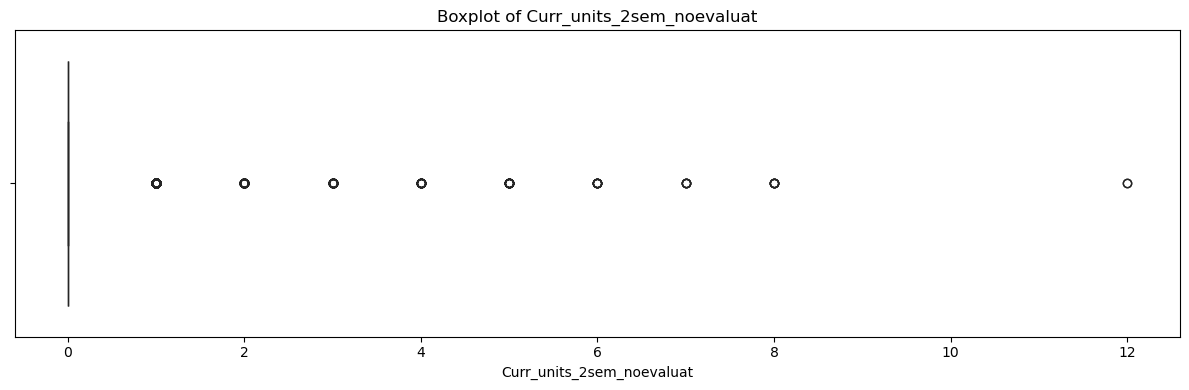

In [152]:
#Boxplot
for i in integ_col:
    plt.figure(figsize=(12, 4))
    
    # Graficar histograma
    sns.boxplot(x=df_clean[i].dropna(), color='purple')
    
    plt.title(f'Boxplot of {i}') 
    plt.xlabel(i)
    
    plt.tight_layout()
    plt.show()

<Figure size 2000x1000 with 0 Axes>

<Axes: >

,Marital_status,Appl_mode,Appl_order,Course,Day/evening attend,Prev_qualif,Prev_qualif_grade,Nationality,Mother's_qualif,Father's_qualif,...,Curr_units_2sem_cred,Curr_units_2sem_enrol,Curr_units_2sem_eval,Curr_units_2sem_appvd,Curr_units_2sem_grade,Curr_units_2sem_noevaluat,Unemploy_rate,Infl_rate,GDP,Target
Marital_status,1.000000,0.264321,-0.125847,0.046445,-0.274922,0.062507,-0.022694,-0.008860,0.193119,0.130511,...,0.062813,0.039076,0.022854,-0.043772,-0.071495,0.020413,-0.020394,0.008666,-0.027101,NaN
Appl_mode,0.264321,1.000000,-0.286096,0.065429,-0.304283,0.421949,-0.039021,-0.000579,0.118634,0.083135,...,0.238425,0.130320,0.167917,-0.071283,-0.115759,0.048060,0.089159,-0.016230,-0.023042,NaN
Appl_order,-0.125847,-0.286096,1.000000,0.059564,0.158600,-0.184261,-0.064403,-0.022408,-0.064712,-0.050036,...,-0.125768,0.028473,-0.054982,0.071689,0.055500,-0.015715,-0.098499,-0.011019,0.030034,NaN
Course,0.046445,0.065429,0.059564,1.000000,-0.043207,0.006604,-0.080865,-0.033903,0.054633,0.050644,...,-0.089794,0.401625,0.278935,0.198083,0.348718,0.030848,0.007238,0.017875,-0.020205,NaN
Day/evening attend,-0.274922,-0.304283,0.158600,-0.043207,1.000000,-0.071871,0.052839,0.018540,-0.204767,-0.139987,...,-0.111953,0.000308,0.014610,0.034022,0.050476,-0.004229,0.061974,-0.024043,0.022929,NaN
Prev_qualif,0.062507,0.421949,-0.184261,0.006604,-0.071871,1.000000,0.104867,-0.029155,-0.013190,-0.006539,...,0.143031,0.056247,0.114850,-0.008632,0.000960,0.005102,0.111958,-0.063736,0.064069,NaN
Prev_qualif_grade,-0.022694,-0.039021,-0.064403,-0.080865,0.052839,0.104867,1.000000,0.054025,-0.061380,-0.035174,...,-0.018673,-0.032027,-0.061368,0.050328,0.053787,-0.019147,0.044745,0.018610,-0.051758,NaN
Nationality,-0.008860,-0.000579,-0.022408,-0.033903,0.018540,-0.029155,0.054025,1.000000,-0.049988,-0.085271,...,-0.007286,-0.020095,-0.025684,-0.017884,-0.008476,-0.014046,-0.000642,-0.008937,0.034503,NaN
Mother's_qualif,0.193119,0.118634,-0.064712,0.054633,-0.204767,-0.013190,-0.061380,-0.049988,1.000000,0.535028,...,0.042771,0.035159,0.021033,-0.014858,-0.031236,0.021305,-0.114351,0.059441,-0.083657,NaN
Father's_qualif,0.130511,0.083135,-0.050036,0.050644,-0.139987,-0.006539,-0.035174,-0.085271,0.535028,1.000000,...,0.042733,0.024224,0.009628,0.005606,-0.007711,-0.007388,-0.077876,0.057739,-0.071817,NaN


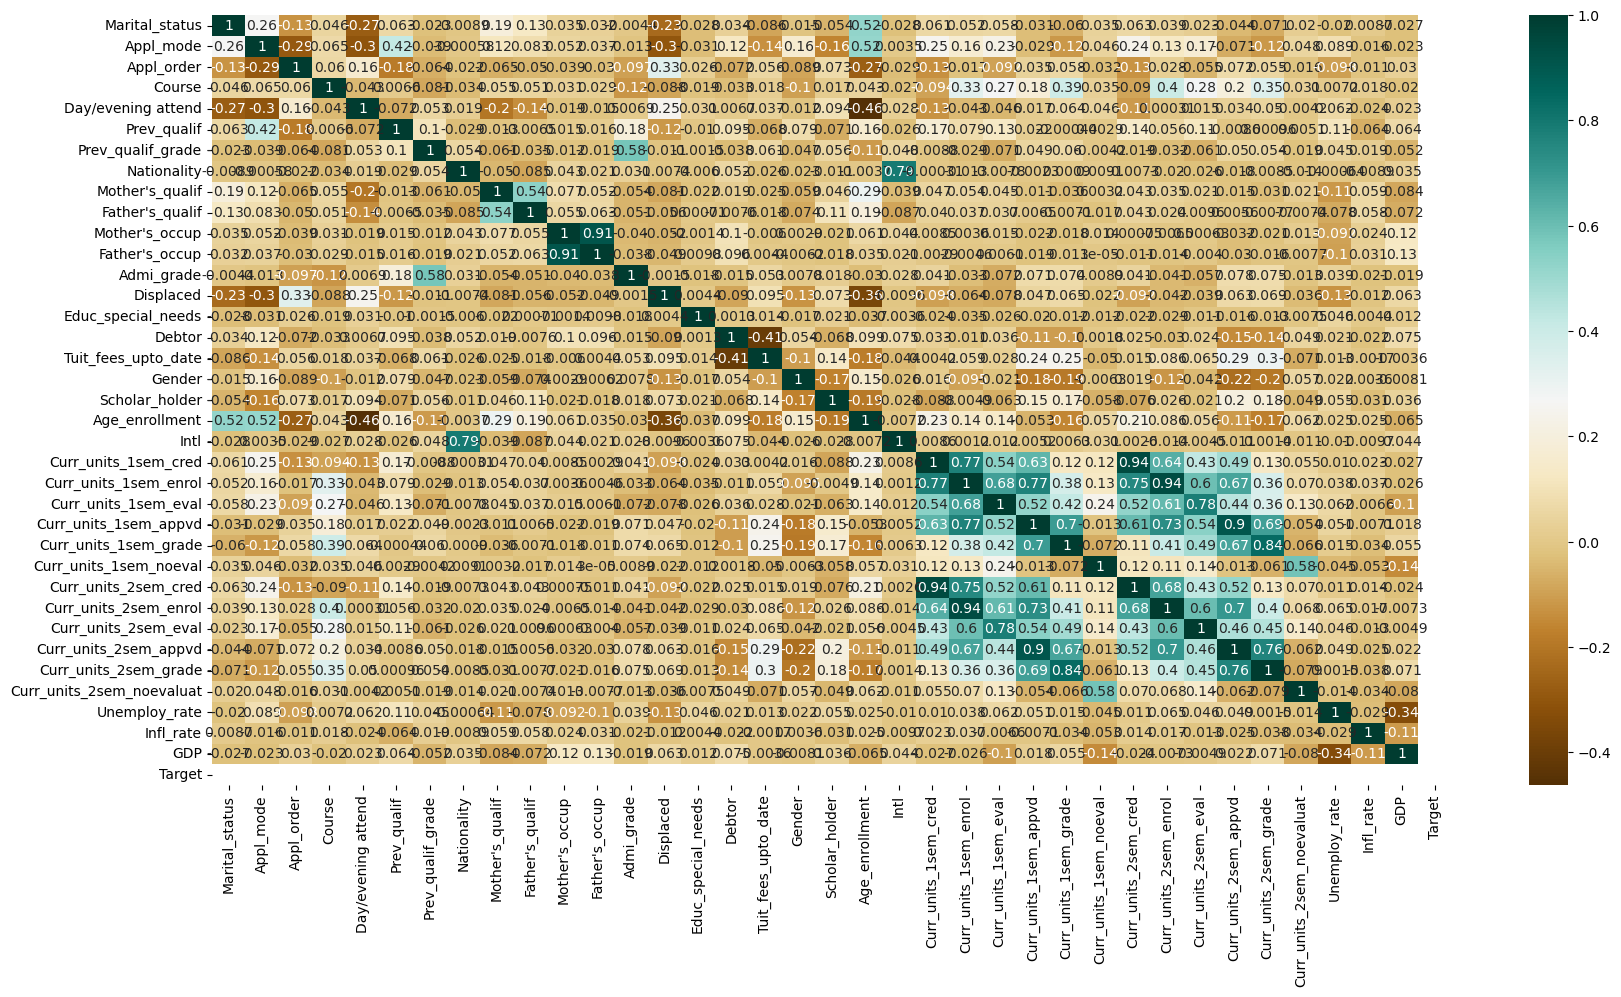

In [154]:
#Heatmap
df_clean['Target'] = df_clean['Target'].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(20,10))
c= df_clean.corr()
sns.heatmap(c,cmap="BrBG",annot=True)
c

Text(0.5, 0, 'Curr_units_2sem_noevaluat')

Text(0, 0.5, 'GDP')

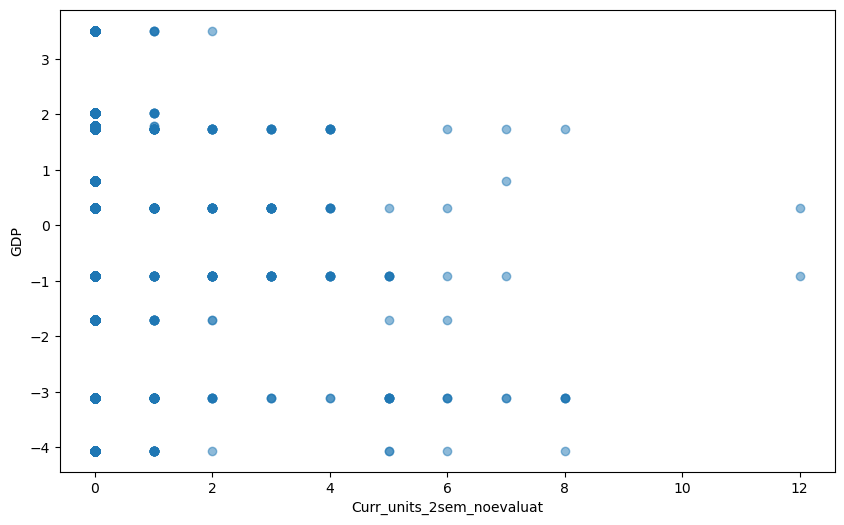

In [156]:
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(df_clean[i], df_clean["GDP"], alpha=0.5)
ax.set_xlabel(i)
ax.set_ylabel("GDP")
plt.show()

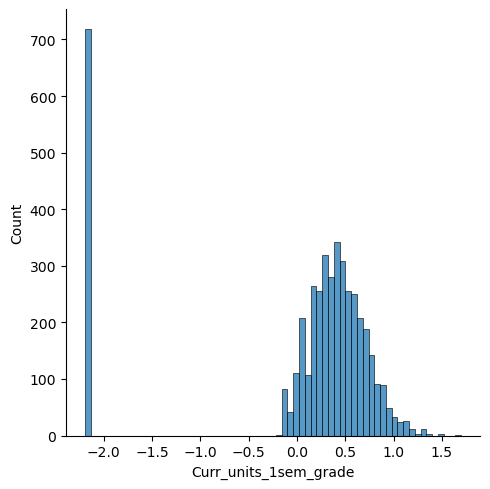

In [182]:
sns.displot(df_clean,x='Curr_units_1sem_grade')

In [184]:
df_clean['Curr_units_1sem_grade']=preproc.StandardScaler().fit_transform(df_clean[['Curr_units_1sem_grade']])

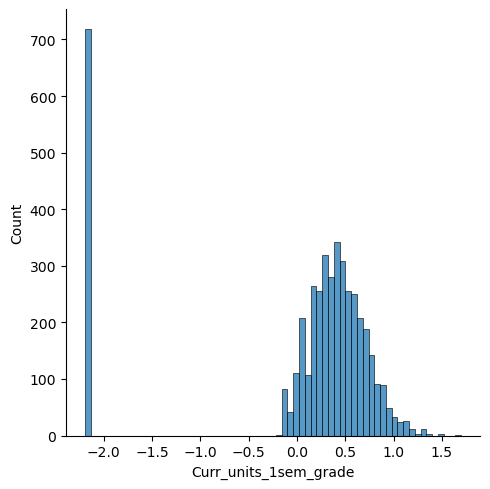

In [186]:
sns.displot(df_clean,x='Curr_units_1sem_grade')

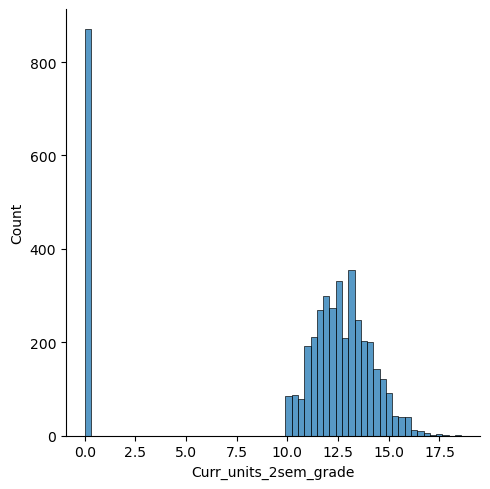

In [188]:
sns.displot(df_clean,x='Curr_units_2sem_grade')

In [190]:
df_clean['Curr_units_2sem_grade']=preproc.StandardScaler().fit_transform(df_clean[['Curr_units_2sem_grade']])

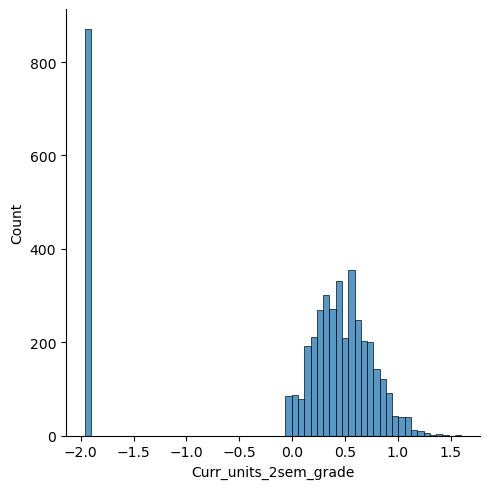

In [192]:
sns.displot(df_clean,x='Curr_units_2sem_grade')

# PCA

In [216]:
rng = np.random.RandomState(1)

In [218]:
X = np.dot(rng.rand(2,2),rng.randn(2,200)).T

(np.float64(-2.7292712056271964),
 np.float64(2.5702744393352615),
 np.float64(-0.9326181575178751),
 np.float64(1.004413830229183))

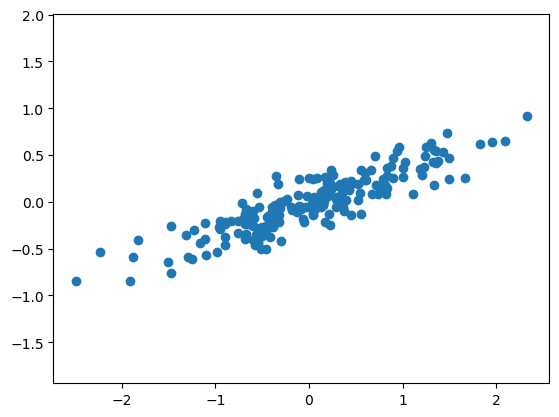

In [220]:
plt.scatter(X[:,0],X[:,1])
plt.axis("equal")

In [222]:
pca= PCA(n_components = 2)
pca.fit(X)
PCA(copy=True, n_components=2, whiten=False)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [224]:
print(pca.components_) 

[[ 0.94446029  0.32862557]
 [-0.32862557  0.94446029]]


In [226]:
print(pca.explained_variance_) 

[0.7625315 0.0184779]


In [228]:
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    arrowprops=dict(arrowstyle='->',
                    linewidth=2,
                    shrinkA=0, shrinkB=0)
    ax.annotate('', v1, v0, arrowprops=arrowprops)

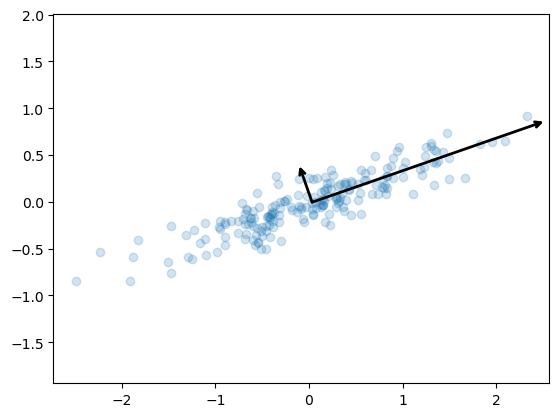

In [230]:
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)
for length, vector in zip(pca.explained_variance_, pca.components_):
    v = vector * 3 * np.sqrt(length)
    draw_vector(pca.mean_, pca.mean_ + v)
plt.axis('equal');

In [232]:
pca = PCA(n_components=1) 
pca.fit(X) 
X_pca = pca.transform(X)
print("original shape:   ", X.shape) 
print("transformed shape:", X_pca.shape) 

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",1
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

original shape:    (200, 2)
transformed shape: (200, 1)


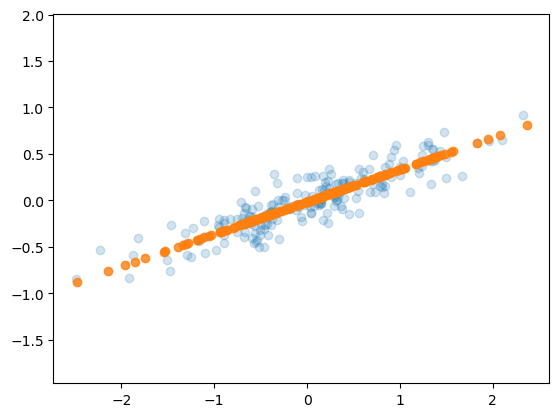

In [234]:
X_new = pca.inverse_transform(X_pca) 
plt.scatter(X[:, 0], X[:, 1], alpha=0.2) 
plt.scatter(X_new[:, 0], X_new[:, 1], alpha=0.8) 
plt.axis('equal'); 

In [241]:
digits = load_digits()

In [243]:
digits.data.shape

(1797, 64)

In [245]:
pca =PCA(2)
projected = pca.fit_transform(digits.data)

In [247]:
digits.data.shape

(1797, 64)

In [249]:
projected.shape

(1797, 2)

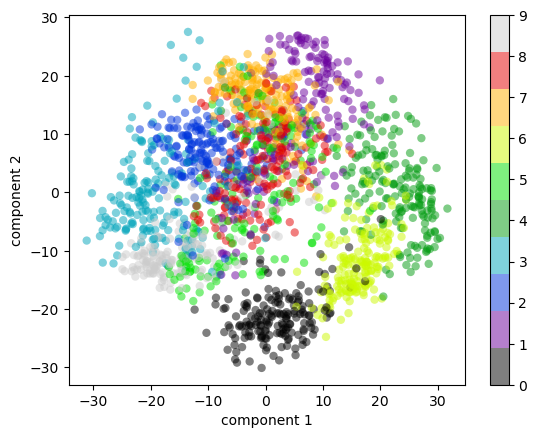

In [251]:
plt.scatter(projected[:,0],projected[:,1],
           c=digits.target, edgecolor="none", alpha=0.5,
           cmap=plt.cm.get_cmap("nipy_spectral",10))
plt.xlabel('component 1') 
plt.ylabel('component 2') 
plt.colorbar();

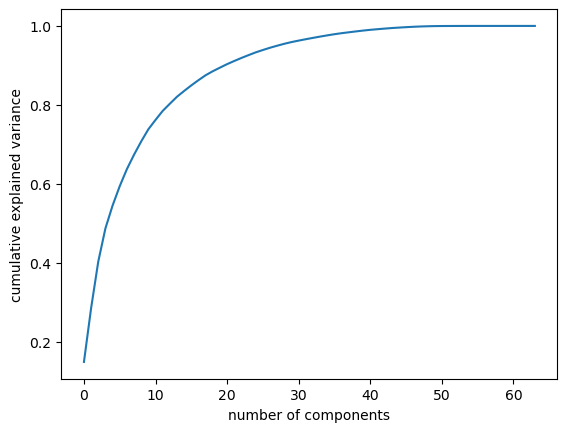

In [253]:
pca = PCA().fit(digits.data) 
plt.plot(np.cumsum(pca.explained_variance_ratio_)) 
plt.xlabel('number of components') 
plt.ylabel('cumulative explained variance'); 

<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Número de componentes principales')

Text(0, 0.5, 'Varianza explicada acumulada')

Text(0.5, 1.0, 'Curva de Codo de PCA')

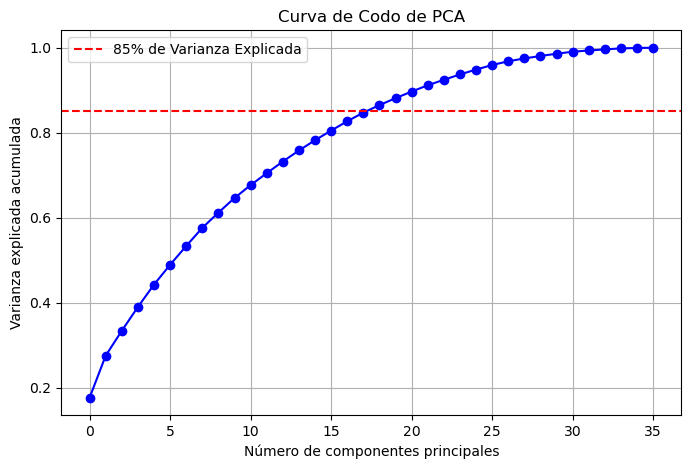

In [214]:
REVISAR

# 1. Separar las características (X) eliminando la etiqueta (Target)
X = df_clean.drop(columns=["Target"], errors='ignore')

# 2. Filtrar para usar únicamente columnas con valores numéricos
X_numeric = X.select_dtypes(include=[np.number])

# 3. Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# 4. Ajustar el PCA
pca = PCA().fit(X_scaled)

# 5. Graficar la varianza explicada acumulada
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', color='b')
plt.axhline(y=0.85, color='r', linestyle='--', label='85% de Varianza Explicada')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('Curva de Codo de PCA')
plt.legend()
plt.grid(True)
plt.show()